In [1]:
%pip install nba_api
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from nba_api.stats.endpoints import leaguedashteamstats
import pandas as pd
import time
print("NBA API is ready!")

NBA API is ready!


In [3]:

seasons = [
    f"{year}-{str(year + 1)[-2:]}"
    for year in range(2000, 2025)
]

all_seasons = []

for season in seasons:
    
    print(f"Downloading {season}...")
    
    stats = leaguedashteamstats.LeagueDashTeamStats(
        season=season,
        season_type_all_star="Regular Season",
        per_mode_detailed="PerGame"
    )
    
    df = stats.get_data_frames()[0]
    
    # Keep the variables we need
    df = df[
        [
            "TEAM_NAME",
            "GP",
            "FGA",
            "FG3A",
            "FG3M",
            "FG3_PCT",
            "PTS",
            "W_PCT",
            "W",
            "L",
            "OREB",      # Offensive rebounds
            "DREB",      # Defensive rebounds
            "REB",       # Total rebounds
            "AST",       # Assists
            "TOV",       # Turnovers
        ]
    ].copy()
    
    # Add season
    df["SEASON"] = season
    
    # Store this season
    all_seasons.append(df)
    
    # Pause briefly between requests
    time.sleep(1)

In [42]:
for season in all_seasons:
    print(season.columns)
    print(season.head())

Index(['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT',
       'W', 'L', 'OREB', 'DREB', 'REB', 'AST', 'TOV', 'SEASON'],
      dtype='str')
             TEAM_NAME  GP   FGA  FG3A  FG3M  FG3_PCT   PTS  W_PCT   W   L  \
0        Atlanta Hawks  82  81.3  11.4   4.1    0.357  91.0  0.305  25  57   
1       Boston Celtics  82  79.1  19.9   7.2    0.363  94.6  0.439  36  46   
2    Charlotte Hornets  82  79.3  12.0   4.1    0.346  91.9  0.561  46  36   
3        Chicago Bulls  82  78.2  11.6   4.0    0.346  87.6  0.183  15  67   
4  Cleveland Cavaliers  82  79.7   8.0   2.7    0.334  92.2  0.366  30  52   

   OREB  DREB   REB   AST   TOV   SEASON  
0  12.5  30.4  42.9  19.0  16.7  2000-01  
1  10.9  28.9  39.8  20.8  15.7  2000-01  
2  12.6  31.8  44.4  23.2  14.4  2000-01  
3  11.3  27.6  38.9  22.1  15.8  2000-01  
4  12.4  29.8  42.1  20.8  16.5  2000-01  
Index(['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT',
       'W', 'L', 'OREB', 'DREB', 'REB

In [43]:
avg_3pm = []
avg_3pa = []
avg_3pp = []
for season in all_seasons:
    avg_3pm.append(season['FG3M'].mean().round(2))
    avg_3pa.append(season['FG3A'].mean().round(2))
    avg_3pp.append(season['FG3_PCT'].mean().round(4))

print(avg_3pm)
print(avg_3pa)
print(avg_3pp)
   
    

[np.float64(4.84), np.float64(5.21), np.float64(5.13), np.float64(5.18), np.float64(5.6), np.float64(5.73), np.float64(6.07), np.float64(6.56), np.float64(6.65), np.float64(6.44), np.float64(6.46), np.float64(6.41), np.float64(7.16), np.float64(7.74), np.float64(7.85), np.float64(8.51), np.float64(9.65), np.float64(10.49), np.float64(11.36), np.float64(12.19), np.float64(12.71), np.float64(12.44), np.float64(12.34), np.float64(12.84), np.float64(13.54)]
[np.float64(13.71), np.float64(14.76), np.float64(14.68), np.float64(14.92), np.float64(15.75), np.float64(15.98), np.float64(16.94), np.float64(18.11), np.float64(18.13), np.float64(18.14), np.float64(18.01), np.float64(18.39), np.float64(19.97), np.float64(21.54), np.float64(22.41), np.float64(24.08), np.float64(27.0), np.float64(29.0), np.float64(32.01), np.float64(34.1), np.float64(34.64), np.float64(35.18), np.float64(34.21), np.float64(35.11), np.float64(37.58)]
[np.float64(0.3518), np.float64(0.3518), np.float64(0.3466), np.float

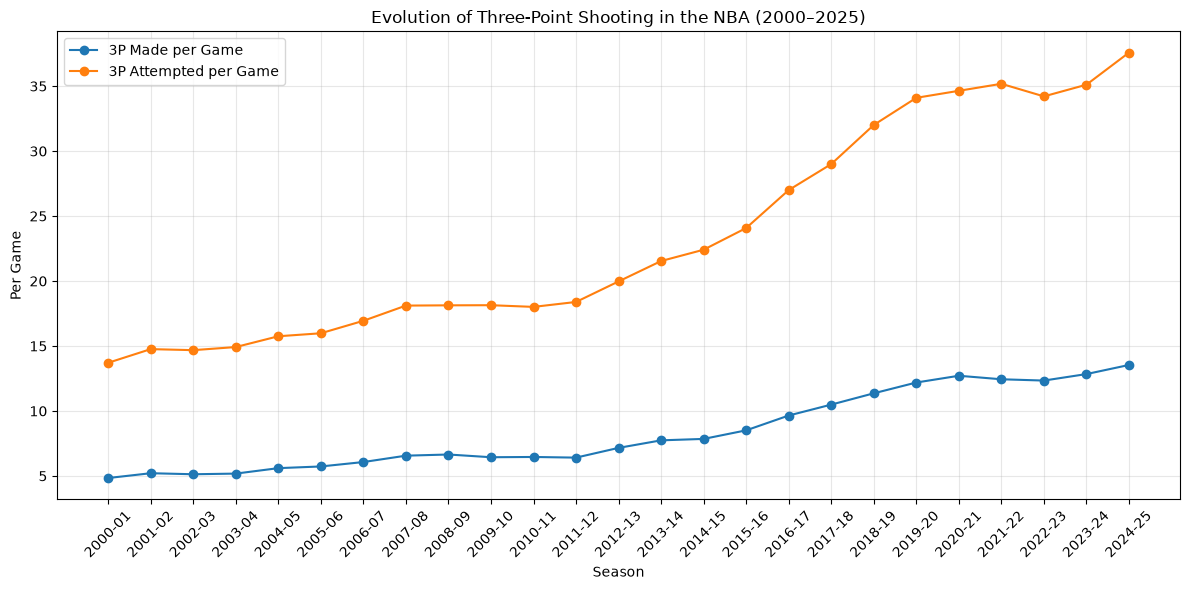

In [44]:
import matplotlib.pyplot as plt

seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pm, marker='o', label='3P Made per Game')
plt.plot(seasons, avg_3pa, marker='o', label='3P Attempted per Game')

plt.xlabel('Season')
plt.ylabel('Per Game')
plt.title('Evolution of Three-Point Shooting in the NBA (2000–2025)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

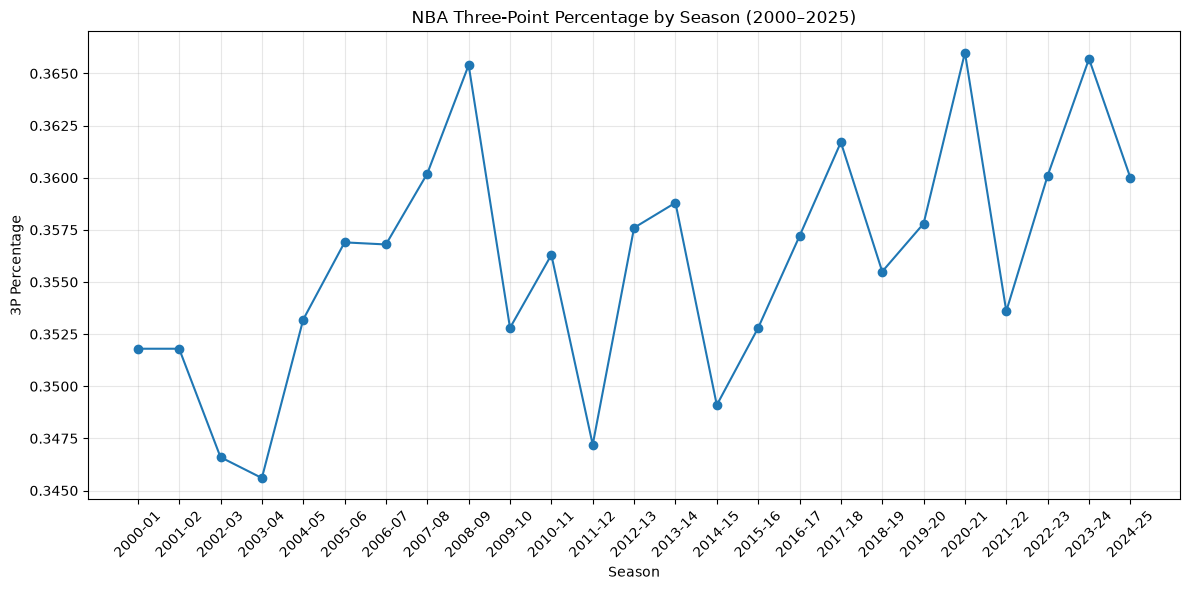

In [45]:
plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pp, marker='o', label='3P%')

plt.xlabel('Season')
plt.ylabel('3P Percentage')
plt.title('NBA Three-Point Percentage by Season (2000–2025)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

import pandas as pd
import matplotlib.pyplot as plt

plot_data = []

for i, season in enumerate(all_seasons):
    temp = season[['TEAM_NAME', 'FG3M', 'W_PCT']].copy()

    # Add the season label
    temp['Season'] = seasons[i]

    plot_data.append(temp)

plot_df = pd.concat(plot_data, ignore_index=True)

print(plot_df.head())

             TEAM_NAME  FG3M  W_PCT   Season
0        Atlanta Hawks   4.1  0.305  2000-01
1       Boston Celtics   7.2  0.439  2000-01
2    Charlotte Hornets   4.1  0.561  2000-01
3        Chicago Bulls   4.0  0.183  2000-01
4  Cleveland Cavaliers   2.7  0.366  2000-01


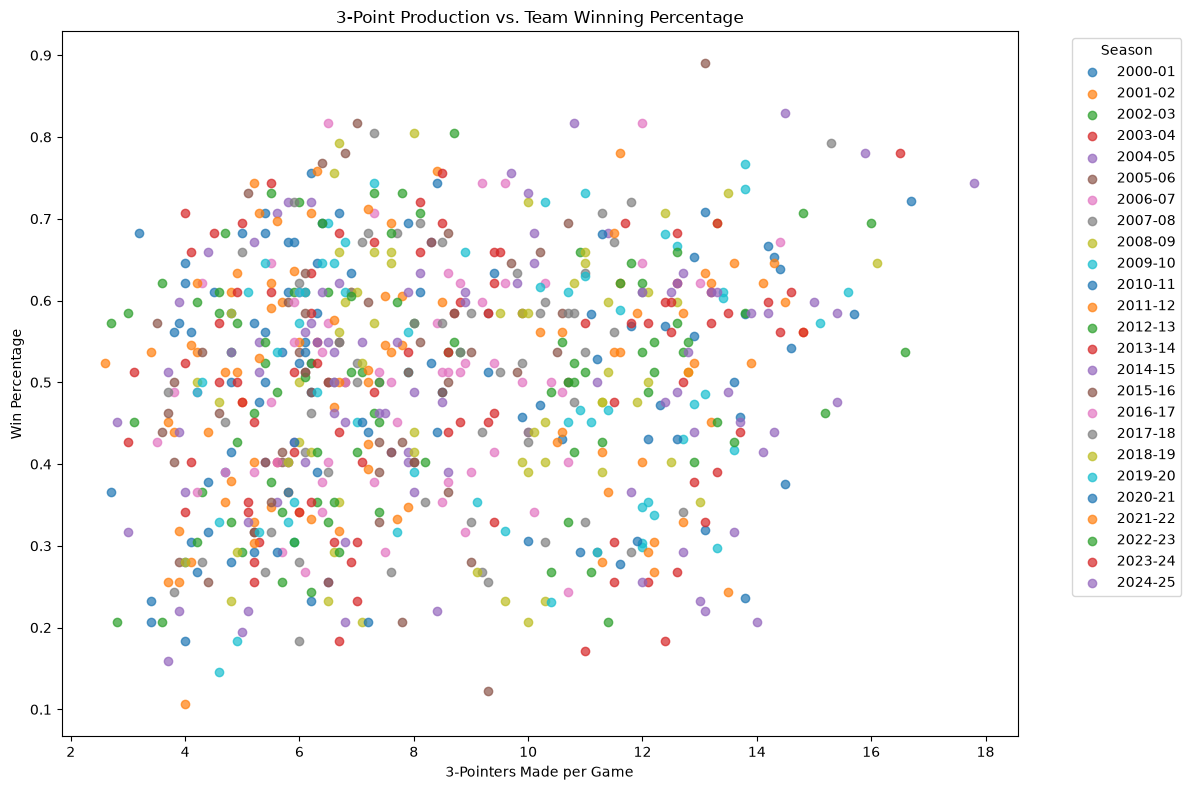

In [47]:
plt.figure(figsize=(12, 8))

for season_name, group in plot_df.groupby('Season'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=season_name,
        alpha=0.7
    )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

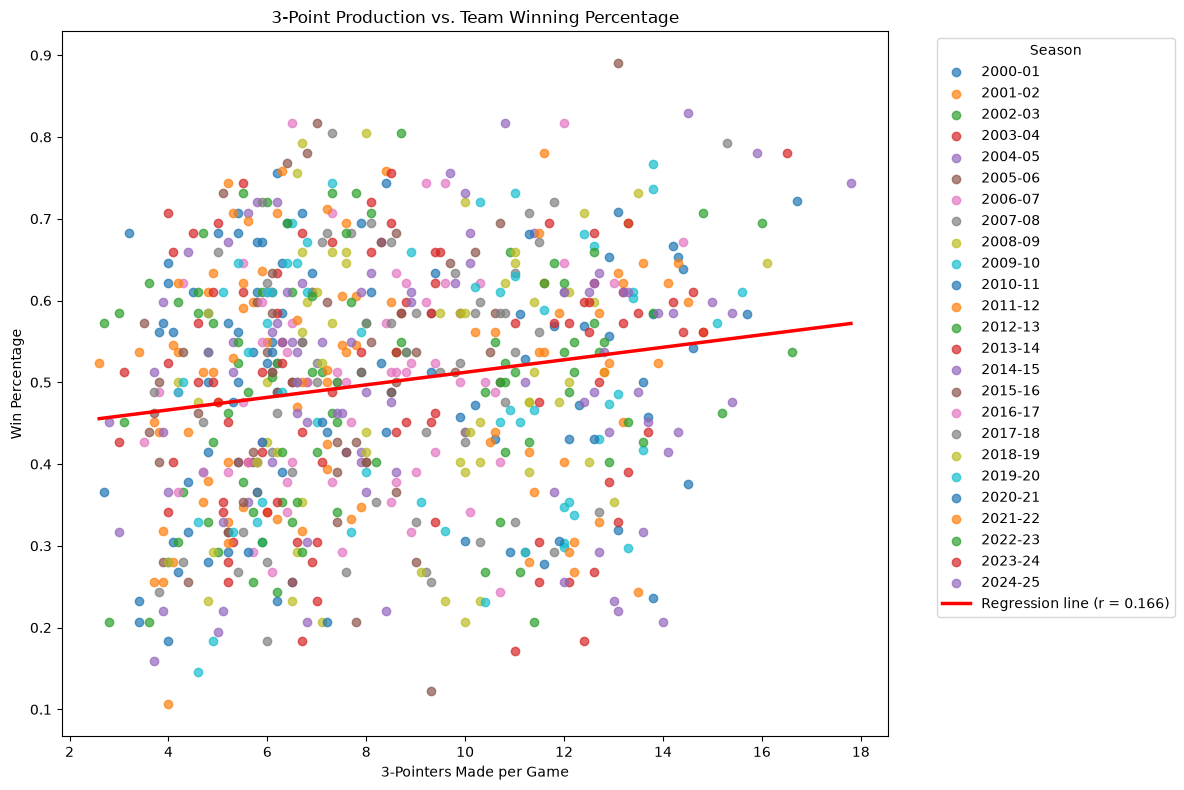

In [48]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for season_name, group in plot_df.groupby('Season'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=season_name,
        alpha=0.7
    )

# Calculate the overall correlation and regression line
x = plot_df['FG3M']
y = plot_df['W_PCT']

slope, intercept = np.polyfit(x, y, 1)
correlation = x.corr(y)

# Draw the regression line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2.5,
    label=f'Regression line (r = {correlation:.3f})'
)

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

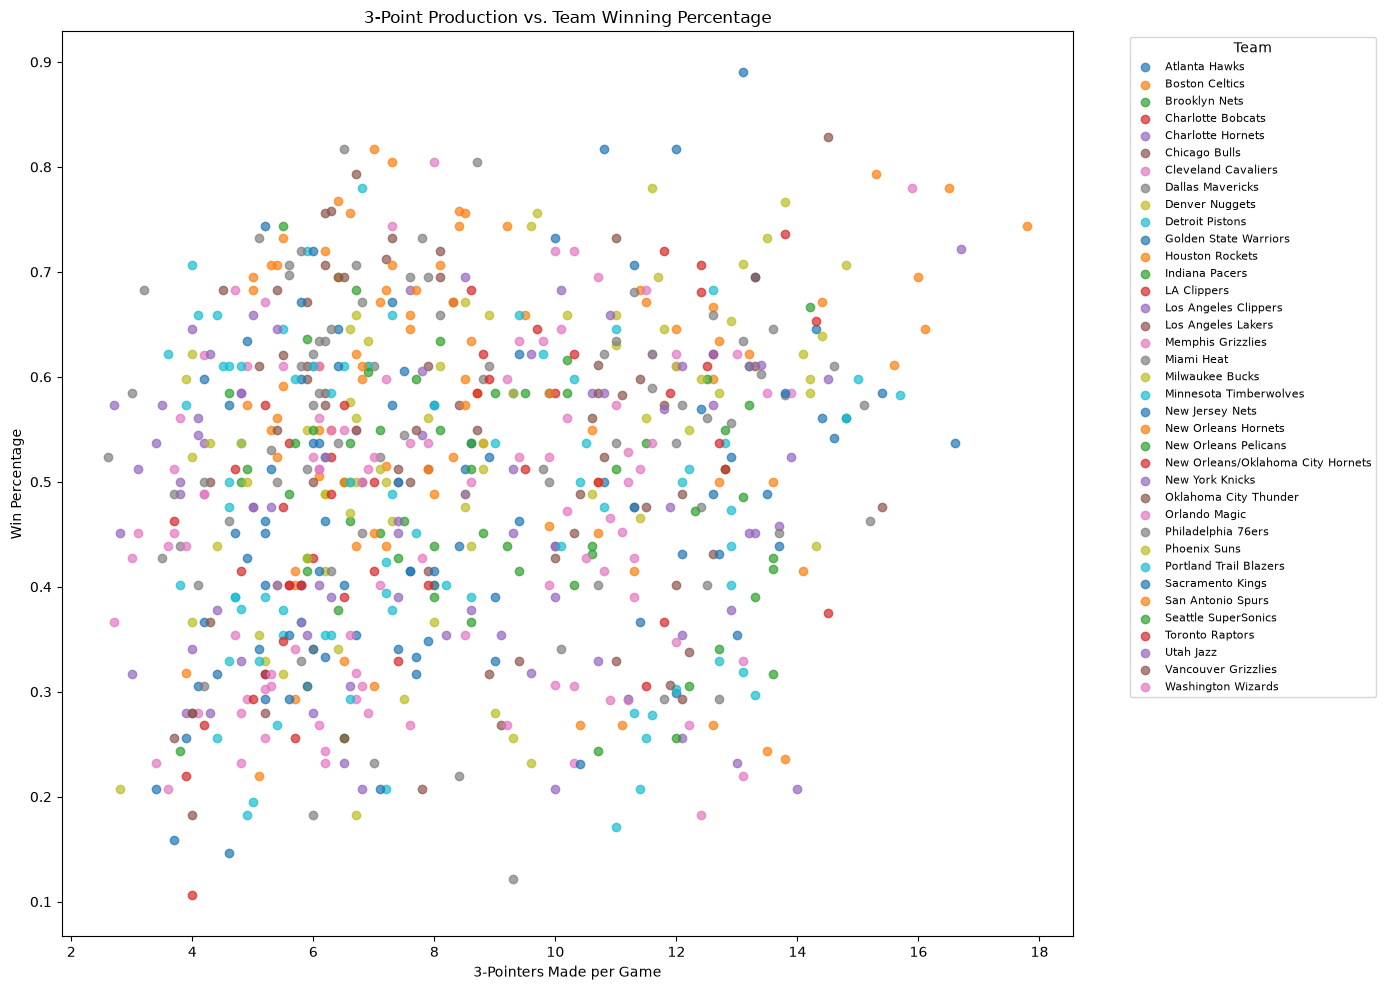

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

for team, group in plot_df.groupby('TEAM_NAME'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=team,
        alpha=0.7
    )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')

plt.legend(
    title='Team',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=8
)

plt.tight_layout()
plt.show()

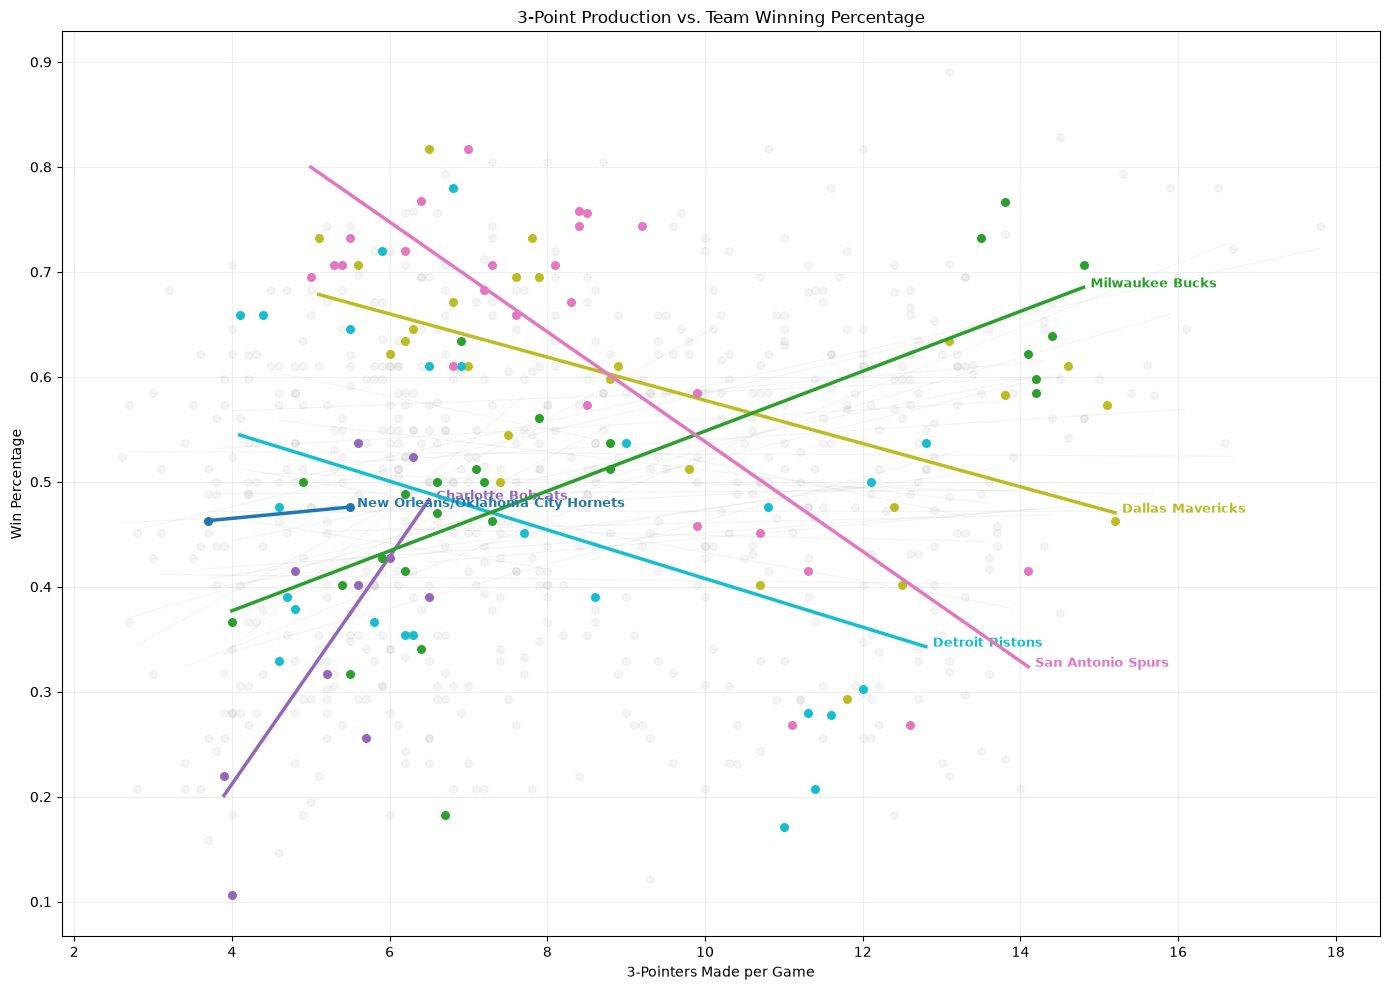

Top 3 positive correlations:
New Orleans/Oklahoma City Hornets: r = 1.000
Milwaukee Bucks: r = 0.763
Charlotte Bobcats: r = 0.713

Top 3 negative correlations:
San Antonio Spurs: r = -0.784
Dallas Mavericks: r = -0.556
Detroit Pistons: r = -0.416


In [50]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate correlation for each team
correlations = {}

for team, group in plot_df.groupby('TEAM_NAME'):
    if len(group) >= 2 and group['FG3M'].nunique() >= 2:
        correlations[team] = group['FG3M'].corr(group['W_PCT'])

# Identify top 3 positive and negative correlations
top_positive = sorted(correlations, key=correlations.get, reverse=True)[:3]
top_negative = sorted(correlations, key=correlations.get)[:3]

highlighted = top_positive + top_negative

# Assign a unique color to each highlighted team
colors = plt.cm.tab10(np.linspace(0, 1, 6))
team_colors = dict(zip(highlighted, colors))

plt.figure(figsize=(14, 10))

for team, group in plot_df.groupby('TEAM_NAME'):
    x = group['FG3M']
    y = group['W_PCT']

    is_highlighted = team in highlighted

    if is_highlighted:
        color = team_colors[team]
        alpha = 1
        linewidth = 2.5
        zorder = 3
    else:
        color = 'gray'
        alpha = 0.08
        linewidth = 1
        zorder = 1

    plt.scatter(x, y, color=color, alpha=alpha, s=30, zorder=zorder)

    if len(group) >= 2 and x.nunique() >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        plt.plot(
            x_line, y_line,
            color=color,
            alpha=alpha,
            linewidth=linewidth,
            zorder=zorder
        )

        if is_highlighted:
            plt.annotate(
                team,
                (x_line[-1], y_line[-1]),
                xytext=(5, 0),
                textcoords='offset points',
                color=color,
                fontsize=9,
                fontweight='bold'
            )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Top 3 positive correlations:")
for team in top_positive:
    print(f"{team}: r = {correlations[team]:.3f}")

print("\nTop 3 negative correlations:")
for team in top_negative:
    print(f"{team}: r = {correlations[team]:.3f}")


In [51]:
## Question 3: Factors Associated with Team Success
### Walter's Analysis

In [52]:
# Examine all columns returned by the NBA API
test_df = all_seasons[0]

print(test_df.columns.tolist())

['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT', 'W', 'L', 'OREB', 'DREB', 'REB', 'AST', 'TOV', 'SEASON']


In [53]:
# Combine all NBA seasons into one dataframe
walter_df = pd.concat(all_seasons, ignore_index=True)

# Display the first five rows
walter_df.head()

,TEAM_NAME,GP,FGA,FG3A,FG3M,FG3_PCT,PTS,W_PCT,W,L,OREB,DREB,REB,AST,TOV,SEASON
0,Atlanta Hawks,82,81.3,11.4,4.1,0.357,91.0,0.305,25,57,12.5,30.4,42.9,19.0,16.7,2000-01
1,Boston Celtics,82,79.1,19.9,7.2,0.363,94.6,0.439,36,46,10.9,28.9,39.8,20.8,15.7,2000-01
2,Charlotte Hornets,82,79.3,12.0,4.1,0.346,91.9,0.561,46,36,12.6,31.8,44.4,23.2,14.4,2000-01
3,Chicago Bulls,82,78.2,11.6,4.0,0.346,87.6,0.183,15,67,11.3,27.6,38.9,22.1,15.8,2000-01
4,Cleveland Cavaliers,82,79.7,8.0,2.7,0.334,92.2,0.366,30,52,12.4,29.8,42.1,20.8,16.5,2000-01


In [54]:
print(walter_df.shape)

(746, 16)


In [55]:
walter_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 746 entries, 0 to 745
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TEAM_NAME  746 non-null    str    
 1   GP         746 non-null    int64  
 2   FGA        746 non-null    float64
 3   FG3A       746 non-null    float64
 4   FG3M       746 non-null    float64
 5   FG3_PCT    746 non-null    float64
 6   PTS        746 non-null    float64
 7   W_PCT      746 non-null    float64
 8   W          746 non-null    int64  
 9   L          746 non-null    int64  
 10  OREB       746 non-null    float64
 11  DREB       746 non-null    float64
 12  REB        746 non-null    float64
 13  AST        746 non-null    float64
 14  TOV        746 non-null    float64
 15  SEASON     746 non-null    str    
dtypes: float64(11), int64(3), str(2)
memory usage: 93.4 KB


In [56]:
walter_df[
    ["OREB", "DREB", "REB", "AST", "TOV", "FG3M", "FG3A", "FG3_PCT", "W_PCT"]
].describe().round(3)

,OREB,DREB,REB,AST,TOV,FG3M,FG3A,FG3_PCT,W_PCT
count,746.000,746.000,746.000,746.000,746.000,746.000,746.000,746.000,746.000
mean,10.958,31.869,42.826,22.702,14.360,8.382,23.421,0.356,0.500
std,1.337,2.201,2.071,2.510,1.156,3.239,8.726,0.019,0.149
min,7.600,26.900,36.900,17.400,11.100,2.600,7.800,0.278,0.106
25%,10.000,30.100,41.425,20.900,13.600,5.800,16.400,0.345,0.390
50%,10.900,31.800,42.800,22.400,14.400,7.700,21.350,0.356,0.512
75%,11.875,33.475,44.200,24.300,15.100,11.000,31.200,0.369,0.610
max,16.400,42.200,51.700,31.000,18.500,17.800,48.200,0.416,0.890


In [57]:
# Correlation between offensive rebounds and winning percentage

oreb_corr = walter_df["OREB"].corr(walter_df["W_PCT"])

print(f"Correlation between OREB and W_PCT: {oreb_corr:.3f}")

Correlation between OREB and W_PCT: -0.139


In [58]:
# Compare team statistics with winning percentage

features = [
    "OREB",
    "DREB",
    "REB",
    "AST",
    "TOV",
    "FG3M",
    "FG3A",
    "FG3_PCT"
]

correlations = (
    walter_df[features + ["W_PCT"]]
    .corr()["W_PCT"]
    .drop("W_PCT")
    .sort_values(ascending=False)
)

print(correlations.round(3))

FG3_PCT    0.509
DREB       0.316
AST        0.252
REB        0.248
FG3M       0.166
FG3A       0.100
OREB      -0.139
TOV       -0.375
Name: W_PCT, dtype: float64


In [60]:
# Test advanced NBA team statistics for one season

test_advanced = leaguedashteamstats.LeagueDashTeamStats(
    season="2024-25",
    season_type_all_star="Regular Season",
    per_mode_detailed="PerGame",
    measure_type_detailed_defense="Advanced"
)

test_advanced_df = test_advanced.get_data_frames()[0]

print(test_advanced_df.columns.tolist())

['TEAM_ID', 'TEAM_NAME', 'GP', 'W', 'L', 'W_PCT', 'MIN', 'E_OFF_RATING', 'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING', 'NET_RATING', 'AST_PCT', 'AST_TO', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT', 'REB_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE', 'GP_RANK', 'W_RANK', 'L_RANK', 'W_PCT_RANK', 'MIN_RANK', 'OFF_RATING_RANK', 'DEF_RATING_RANK', 'NET_RATING_RANK', 'AST_PCT_RANK', 'AST_TO_RANK', 'AST_RATIO_RANK', 'OREB_PCT_RANK', 'DREB_PCT_RANK', 'REB_PCT_RANK', 'TM_TOV_PCT_RANK', 'EFG_PCT_RANK', 'TS_PCT_RANK', 'PACE_RANK', 'PIE_RANK']


In [61]:
advanced_seasons = []

for season in seasons:
    
    print(f"Downloading advanced stats for {season}...")
    
    stats = leaguedashteamstats.LeagueDashTeamStats(
        season=season,
        season_type_all_star="Regular Season",
        per_mode_detailed="PerGame",
        measure_type_detailed_defense="Advanced"
    )
    
    df = stats.get_data_frames()[0]
    
    # Keep advanced statistics relevant to our analysis
    df = df[
        [
            "TEAM_NAME",
            "W_PCT",
            "OFF_RATING",
            "DEF_RATING",
            "NET_RATING",
            "OREB_PCT",
            "DREB_PCT",
            "REB_PCT",
            "PACE"
        ]
    ].copy()
    
    # Add season
    df["SEASON"] = season
    
    # Store this season
    advanced_seasons.append(df)
    
    # Pause between API requests
    time.sleep(1)

In [62]:
advanced_df = pd.concat(
    advanced_seasons,
    ignore_index=True
)

print(advanced_df.shape)

advanced_df.head()

(746, 10)


,TEAM_NAME,W_PCT,OFF_RATING,DEF_RATING,NET_RATING,OREB_PCT,DREB_PCT,REB_PCT,PACE,SEASON
0,Atlanta Hawks,0.305,96.9,102.4,-5.5,0.313,0.691,0.501,93.63,2000-01
1,Boston Celtics,0.439,100.1,102.3,-2.2,0.280,0.690,0.478,93.81,2000-01
2,Charlotte Hornets,0.561,99.7,97.6,2.1,0.315,0.710,0.513,91.24,2000-01
3,Chicago Bulls,0.183,95.9,105.9,-10.0,0.302,0.673,0.480,90.47,2000-01
4,Cleveland Cavaliers,0.366,99.3,103.5,-4.2,0.331,0.678,0.505,92.32,2000-01


In [63]:
advanced_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 746 entries, 0 to 745
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   TEAM_NAME   746 non-null    str    
 1   W_PCT       746 non-null    float64
 2   OFF_RATING  746 non-null    float64
 3   DEF_RATING  746 non-null    float64
 4   NET_RATING  746 non-null    float64
 5   OREB_PCT    746 non-null    float64
 6   DREB_PCT    746 non-null    float64
 7   REB_PCT     746 non-null    float64
 8   PACE        746 non-null    float64
 9   SEASON      746 non-null    str    
dtypes: float64(8), str(2)
memory usage: 58.4 KB


In [ ]:

advanced_df.isnull().sum()

TEAM_NAME     0
W_PCT         0
OFF_RATING    0
DEF_RATING    0
NET_RATING    0
OREB_PCT      0
DREB_PCT      0
REB_PCT       0
PACE          0
SEASON        0
dtype: int64

In [65]:
advanced_df.shape

(746, 10)

In [66]:
walter_defense_df = walter_df.merge(
    advanced_df.drop(columns=["W_PCT"]),
    on=["TEAM_NAME", "SEASON"],
    how="inner"
)

print(walter_defense_df.shape)

walter_defense_df.head()

(746, 23)


,TEAM_NAME,GP,FGA,FG3A,FG3M,FG3_PCT,PTS,W_PCT,W,L,...,AST,TOV,SEASON,OFF_RATING,DEF_RATING,NET_RATING,OREB_PCT,DREB_PCT,REB_PCT,PACE
0,Atlanta Hawks,82,81.3,11.4,4.1,0.357,91.0,0.305,25,57,...,19.0,16.7,2000-01,96.9,102.4,-5.5,0.313,0.691,0.501,93.63
1,Boston Celtics,82,79.1,19.9,7.2,0.363,94.6,0.439,36,46,...,20.8,15.7,2000-01,100.1,102.3,-2.2,0.280,0.690,0.478,93.81
2,Charlotte Hornets,82,79.3,12.0,4.1,0.346,91.9,0.561,46,36,...,23.2,14.4,2000-01,99.7,97.6,2.1,0.315,0.710,0.513,91.24
3,Chicago Bulls,82,78.2,11.6,4.0,0.346,87.6,0.183,15,67,...,22.1,15.8,2000-01,95.9,105.9,-10.0,0.302,0.673,0.480,90.47
4,Cleveland Cavaliers,82,79.7,8.0,2.7,0.334,92.2,0.366,30,52,...,20.8,16.5,2000-01,99.3,103.5,-4.2,0.331,0.678,0.505,92.32


In [67]:
walter_defense_df[
    [
        "TEAM_NAME",
        "SEASON",
        "W_PCT",
        "DREB",
        "DREB_PCT",
        "DEF_RATING"
    ]
].head(10)

,TEAM_NAME,SEASON,W_PCT,DREB,DREB_PCT,DEF_RATING
0,Atlanta Hawks,2000-01,0.305,30.4,0.691,102.4
1,Boston Celtics,2000-01,0.439,28.9,0.690,102.3
2,Charlotte Hornets,2000-01,0.561,31.8,0.710,97.6
3,Chicago Bulls,2000-01,0.183,27.6,0.673,105.9
4,Cleveland Cavaliers,2000-01,0.366,29.8,0.678,103.5
5,Dallas Mavericks,2000-01,0.646,31.4,0.678,101.2
6,Denver Nuggets,2000-01,0.488,31.5,0.690,104.9
7,Detroit Pistons,2000-01,0.390,32.0,0.691,100.3
8,Golden State Warriors,2000-01,0.207,29.1,0.680,105.5
9,Houston Rockets,2000-01,0.549,30.8,0.691,102.8


In [68]:
def_rating_corr = walter_defense_df["DEF_RATING"].corr(
    walter_defense_df["W_PCT"]
)

print(
    f"Correlation between DEF_RATING and W_PCT: "
    f"{def_rating_corr:.3f}"
)

Correlation between DEF_RATING and W_PCT: -0.440


In [69]:
# Compare defensive and rebounding metrics with winning percentage

defensive_features = [
    "DEF_RATING",
    "DREB",
    "DREB_PCT",
    "REB",
    "REB_PCT",
    "OREB",
    "OREB_PCT"
]

defensive_correlations = (
    walter_defense_df[
        defensive_features + ["W_PCT"]
    ]
    .corr()["W_PCT"]
    .drop("W_PCT")
    .sort_values(ascending=False)
)

print(defensive_correlations.round(3))

REB_PCT       0.401
DREB          0.316
REB           0.248
DREB_PCT      0.208
OREB_PCT     -0.028
OREB         -0.139
DEF_RATING   -0.440
Name: W_PCT, dtype: float64


In [70]:
# Calculate DEF_RATING vs W_PCT correlation for each NBA season

defense_by_season = (
    walter_defense_df
    .groupby("SEASON")
    .apply(
        lambda x: x["DEF_RATING"].corr(x["W_PCT"]),
        include_groups=False
    )
    .reset_index(name="DEF_RATING_CORR")
)

defense_by_season

,SEASON,DEF_RATING_CORR
0,2000-01,-0.692740
1,2001-02,-0.657128
2,2002-03,-0.554692
3,2003-04,-0.622516
4,2004-05,-0.602555
5,2005-06,-0.710980
6,2006-07,-0.705196
7,2007-08,-0.811799
8,2008-09,-0.844116
9,2009-10,-0.696473


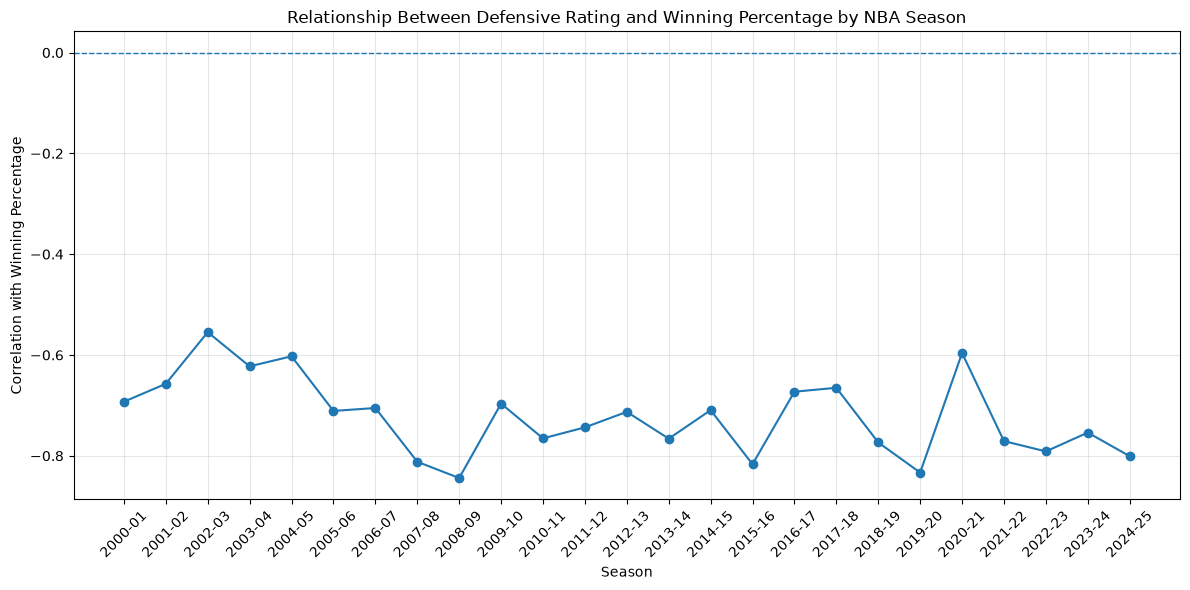

In [71]:
plt.figure(figsize=(12, 6))

plt.plot(
    defense_by_season["SEASON"],
    defense_by_season["DEF_RATING_CORR"],
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Season")
plt.ylabel("Correlation with Winning Percentage")
plt.title(
    "Relationship Between Defensive Rating and Winning Percentage by NBA Season"
)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [72]:
# Compare offensive and defensive rating correlations
# with winning percentage for each season

offense_defense_by_season = (
    walter_defense_df
    .groupby("SEASON")
    .apply(
        lambda x: pd.Series({
            "OFF_RATING_CORR":
                x["OFF_RATING"].corr(x["W_PCT"]),
            
            "DEF_RATING_CORR":
                x["DEF_RATING"].corr(x["W_PCT"])
        }),
        include_groups=False
    )
    .reset_index()
)

offense_defense_by_season.round(3)

,SEASON,OFF_RATING_CORR,DEF_RATING_CORR
0,2000-01,0.788,-0.693
1,2001-02,0.761,-0.657
2,2002-03,0.778,-0.555
3,2003-04,0.548,-0.623
4,2004-05,0.721,-0.603
5,2005-06,0.580,-0.711
6,2006-07,0.661,-0.705
7,2007-08,0.851,-0.812
8,2008-09,0.819,-0.844
9,2009-10,0.781,-0.696


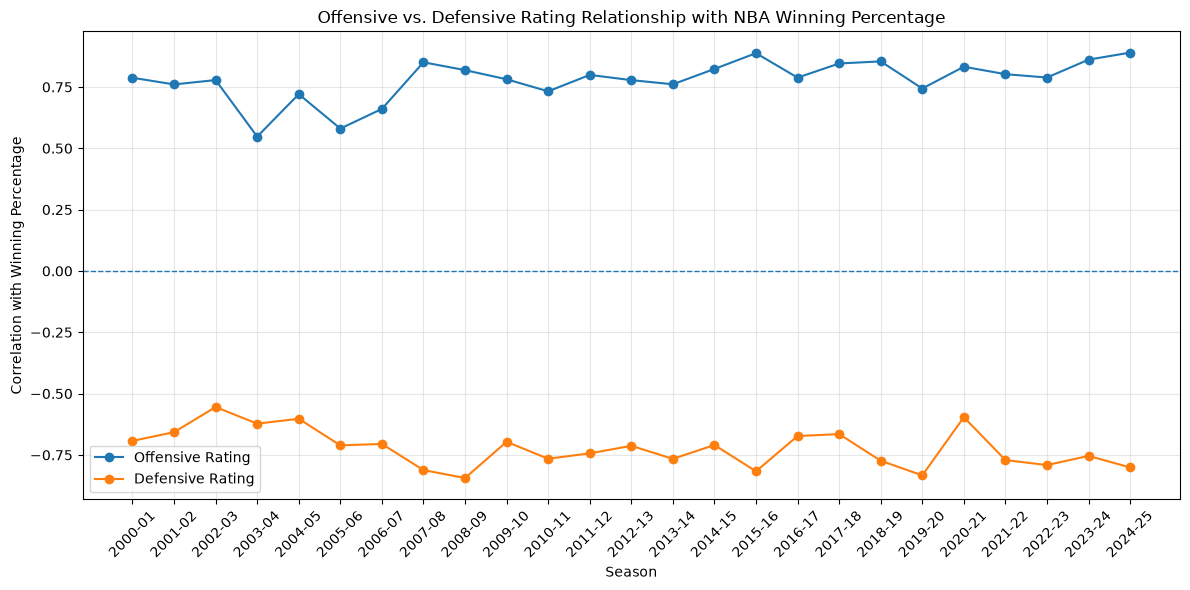

In [73]:
plt.figure(figsize=(12, 6))

plt.plot(
    offense_defense_by_season["SEASON"],
    offense_defense_by_season["OFF_RATING_CORR"],
    marker="o",
    label="Offensive Rating"
)

plt.plot(
    offense_defense_by_season["SEASON"],
    offense_defense_by_season["DEF_RATING_CORR"],
    marker="o",
    label="Defensive Rating"
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.xlabel("Season")
plt.ylabel("Correlation with Winning Percentage")
plt.title(
    "Offensive vs. Defensive Rating Relationship with NBA Winning Percentage"
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [74]:
walter_defense_df["OFF_RANK"] = (
    walter_defense_df
    .groupby("SEASON")["OFF_RATING"]
    .rank(method="min", ascending=False)
)

# Lower defensive rating is better, so ascending=True
walter_defense_df["DEF_RANK"] = (
    walter_defense_df
    .groupby("SEASON")["DEF_RATING"]
    .rank(method="min", ascending=True)
)

walter_defense_df[
    [
        "SEASON",
        "TEAM_NAME",
        "W_PCT",
        "OFF_RATING",
        "OFF_RANK",
        "DEF_RATING",
        "DEF_RANK"
    ]
].head(10)

,SEASON,TEAM_NAME,W_PCT,OFF_RATING,OFF_RANK,DEF_RATING,DEF_RANK
0,2000-01,Atlanta Hawks,0.305,96.9,27.0,102.4,16.0
1,2000-01,Boston Celtics,0.439,100.1,17.0,102.3,15.0
2,2000-01,Charlotte Hornets,0.561,99.7,19.0,97.6,6.0
3,2000-01,Chicago Bulls,0.183,95.9,29.0,105.9,28.0
4,2000-01,Cleveland Cavaliers,0.366,99.3,22.0,103.5,21.0
5,2000-01,Dallas Mavericks,0.646,105.6,4.0,101.2,13.0
6,2000-01,Denver Nuggets,0.488,102.2,12.0,104.9,26.0
7,2000-01,Detroit Pistons,0.390,98.5,24.0,100.3,8.0
8,2000-01,Golden State Warriors,0.207,96.3,28.0,105.5,27.0
9,2000-01,Houston Rockets,0.549,105.2,5.0,102.8,19.0


In [75]:
walter_defense_df[
    walter_defense_df["SEASON"] == "2024-25"
][
    [
        "TEAM_NAME",
        "W_PCT",
        "OFF_RATING",
        "OFF_RANK",
        "DEF_RATING",
        "DEF_RANK"
    ]
].sort_values("DEF_RANK").head(10)

,TEAM_NAME,W_PCT,OFF_RATING,OFF_RANK,DEF_RATING,DEF_RANK
736,Oklahoma City Thunder,0.829,119.2,3.0,106.6,1.0
737,Orlando Magic,0.500,108.9,27.0,109.1,2.0
728,LA Clippers,0.610,114.3,15.0,109.4,3.0
717,Boston Celtics,0.744,119.5,2.0,110.1,4.0
726,Houston Rockets,0.634,114.9,12.0,110.3,5.0
733,Minnesota Timberwolves,0.598,115.7,8.0,110.8,6.0
725,Golden State Warriors,0.585,114.2,16.0,111.0,7.0
721,Cleveland Cavaliers,0.780,121.0,1.0,111.8,8.0
731,Miami Heat,0.451,112.4,21.0,112.0,9.0
724,Detroit Pistons,0.537,114.6,14.0,112.5,10.0


Graph 1 — Defensive Rating vs. Winning Over Time

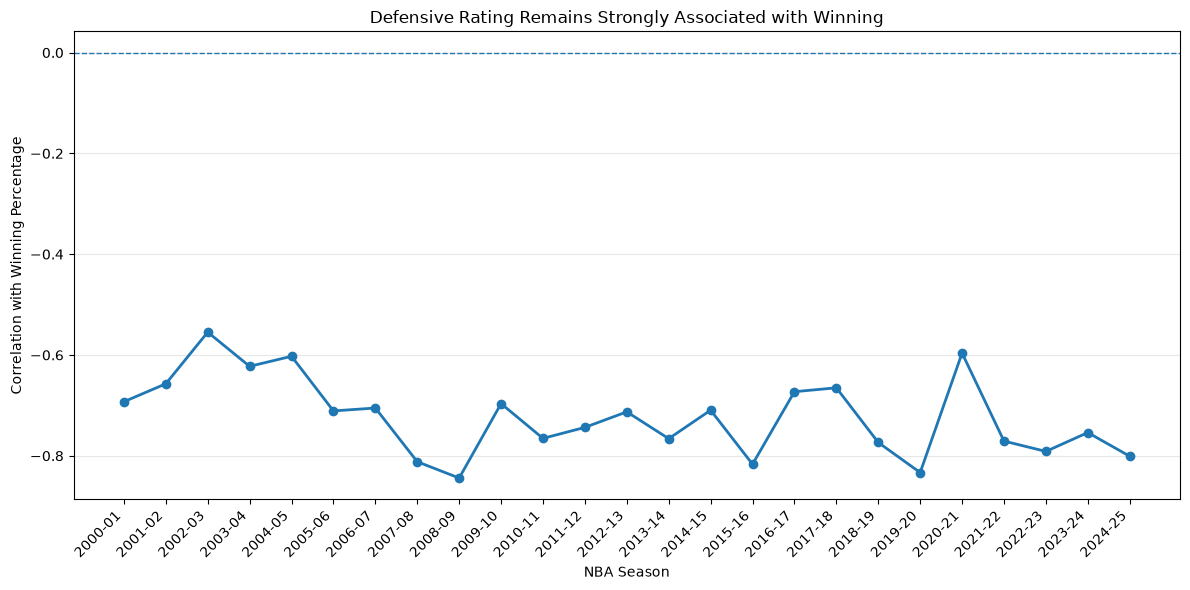

In [76]:
plt.figure(figsize=(12, 6))

plt.plot(
    defense_by_season["SEASON"],
    defense_by_season["DEF_RATING_CORR"],
    marker="o",
    linewidth=2
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.xlabel("NBA Season")
plt.ylabel("Correlation with Winning Percentage")
plt.title(
    "Defensive Rating Remains Strongly Associated with Winning"
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save a high-quality copy for PowerPoint
plt.savefig(
    "defensive_rating_vs_winning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Defensive Rating & Winning
- Defensive rating was negatively correlated with winning percentage in all 25 seasons analyzed (2000–01 to 2024–25).
- Seasonal correlations ranged from approximately −0.55 to −0.84.
- Because lower defensive rating represents better defense, the negative relationship means better defensive teams generally had higher winning percentages.
- The relationship remained consistent despite major changes in NBA offensive strategy over the 25-season period.

Graph 2 — Offense vs. Defense

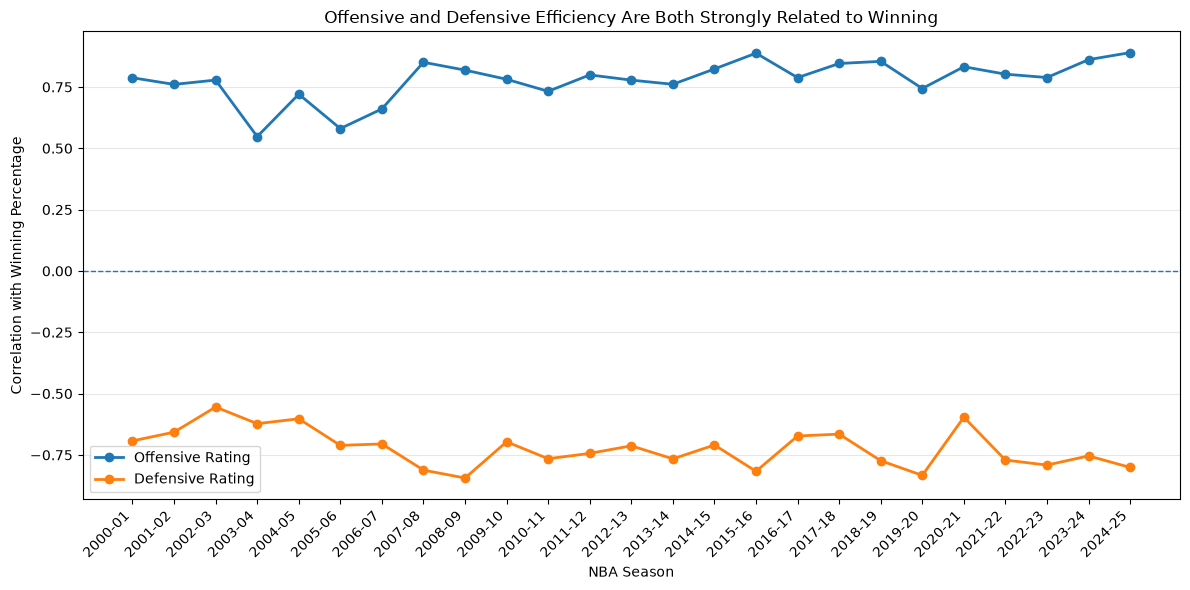

In [78]:
# Offensive vs. Defensive Rating Relationship with Winning

plt.figure(figsize=(12, 6))

plt.plot(
    offense_defense_by_season["SEASON"],
    offense_defense_by_season["OFF_RATING_CORR"],
    marker="o",
    linewidth=2,
    label="Offensive Rating"
)

plt.plot(
    offense_defense_by_season["SEASON"],
    offense_defense_by_season["DEF_RATING_CORR"],
    marker="o",
    linewidth=2,
    label="Defensive Rating"
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.xlabel("NBA Season")
plt.ylabel("Correlation with Winning Percentage")
plt.title(
    "Offensive and Defensive Efficiency Are Both Strongly Related to Winning"
)

plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "offense_vs_defense_winning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Offensive vs. Defensive Efficiency
- Both offensive and defensive ratings showed strong relationships with winning across the 25 seasons.
- Offensive rating was positively correlated with winning, while defensive rating was negatively correlated because lower defensive ratings indicate better defense.
- Neither offense nor defense was consistently stronger across every season.
- The results suggest that successful NBA teams generally benefit from efficiency on both ends of the floor.

 Rebounding and NBA Winning Percentage

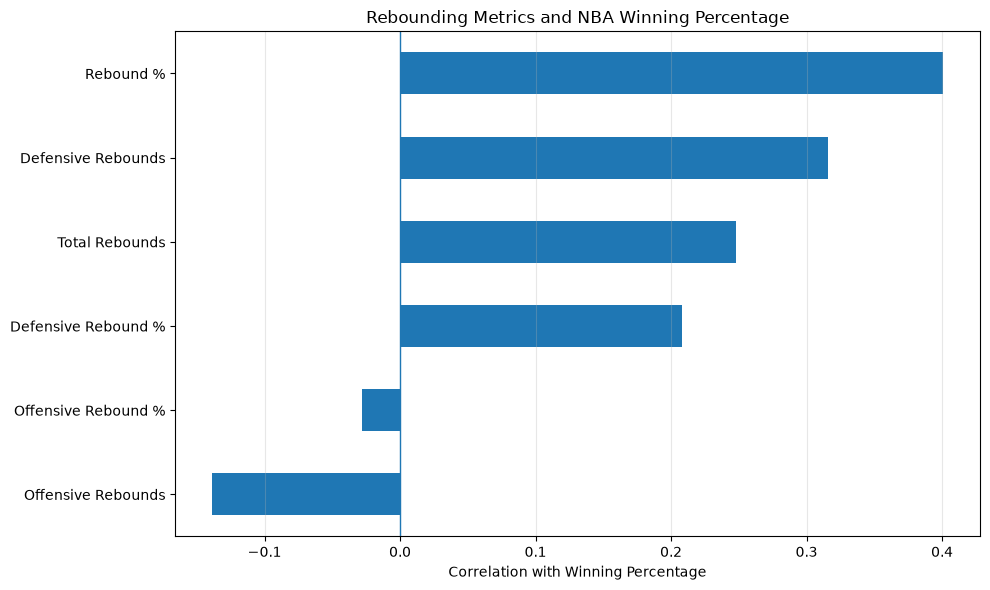

In [80]:
# Rebounding metrics and winning percentage

rebound_corr = pd.Series({
    "Rebound %": 0.401,
    "Defensive Rebounds": 0.316,
    "Total Rebounds": 0.248,
    "Defensive Rebound %": 0.208,
    "Offensive Rebound %": -0.028,
    "Offensive Rebounds": -0.139
})

rebound_corr = rebound_corr.sort_values()

plt.figure(figsize=(10, 6))

rebound_corr.plot(kind="barh")

plt.axvline(x=0, linewidth=1)

plt.xlabel("Correlation with Winning Percentage")
plt.ylabel("")
plt.title("Rebounding Metrics and NBA Winning Percentage")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "rebounding_vs_winning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The original hypothesis focused on offensive rebounding, but OREB showed a weak negative relationship with winning (r = −0.139).
Defensive rebounds showed a stronger positive relationship (r = +0.316).
Overall rebound percentage produced the strongest rebounding relationship (r = +0.401).
These results motivated a broader investigation into defensive efficiency rather than offensive rebounding alone.

In [81]:
%pip install -U kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [kagglehub]/3 [kagglesdk]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [82]:
import kagglehub
from pathlib import Path

ranking_path = kagglehub.dataset_download(
    "nathanlauga/nba-games",
    path="ranking.csv"
)

ranking_df = pd.read_csv(ranking_path)

print("Downloaded file:", ranking_path)
print("Dataset shape:", ranking_df.shape)
print(ranking_df.columns.tolist())

ranking_df.head()

100%|██████████| 1.25M/1.25M [00:00<00:00, 17.2MB/s]

Extracting zip of ranking.csv...
Downloaded file: /Users/worldclass/.cache/kagglehub/datasets/nathanlauga/nba-games/versions/10/ranking.csv
Dataset shape: (210342, 13)
['TEAM_ID', 'LEAGUE_ID', 'SEASON_ID', 'STANDINGSDATE', 'CONFERENCE', 'TEAM', 'G', 'W', 'L', 'W_PCT', 'HOME_RECORD', 'ROAD_RECORD', 'RETURNTOPLAY']


,TEAM_ID,LEAGUE_ID,SEASON_ID,STANDINGSDATE,CONFERENCE,TEAM,G,W,L,W_PCT,HOME_RECORD,ROAD_RECORD,RETURNTOPLAY
0,1610612743,0,22022,2022-12-22,West,Denver,30,19,11,0.633,10-3,9-8,NaN
1,1610612763,0,22022,2022-12-22,West,Memphis,30,19,11,0.633,13-2,6-9,NaN
2,1610612740,0,22022,2022-12-22,West,New Orleans,31,19,12,0.613,13-4,6-8,NaN
3,1610612756,0,22022,2022-12-22,West,Phoenix,32,19,13,0.594,14-4,5-9,NaN
4,1610612746,0,22022,2022-12-22,West,LA Clippers,33,19,14,0.576,11-7,8-7,NaN


In [83]:
ranking_df["STANDINGSDATE"] = pd.to_datetime(
    ranking_df["STANDINGSDATE"]
)

print(ranking_df["STANDINGSDATE"].min())
print(ranking_df["STANDINGSDATE"].max())
print(ranking_df["SEASON_ID"].unique()[:15])
print(ranking_df.isna().sum())

ranking_df.head()

2003-10-01 00:00:00
2022-12-22 00:00:00
[22022 12022 22021 12021 22020 12020 22019 12019 22013 12013 22012 12012
 22011 12011 22010]
TEAM_ID               0
LEAGUE_ID             0
SEASON_ID             0
STANDINGSDATE         0
CONFERENCE            0
TEAM                  0
G                     0
W                     0
L                     0
W_PCT                 0
HOME_RECORD           0
ROAD_RECORD           0
RETURNTOPLAY     206352
dtype: int64


,TEAM_ID,LEAGUE_ID,SEASON_ID,STANDINGSDATE,CONFERENCE,TEAM,G,W,L,W_PCT,HOME_RECORD,ROAD_RECORD,RETURNTOPLAY
0,1610612743,0,22022,2022-12-22,West,Denver,30,19,11,0.633,10-3,9-8,NaN
1,1610612763,0,22022,2022-12-22,West,Memphis,30,19,11,0.633,13-2,6-9,NaN
2,1610612740,0,22022,2022-12-22,West,New Orleans,31,19,12,0.613,13-4,6-8,NaN
3,1610612756,0,22022,2022-12-22,West,Phoenix,32,19,13,0.594,14-4,5-9,NaN
4,1610612746,0,22022,2022-12-22,West,LA Clippers,33,19,14,0.576,11-7,8-7,NaN


In [84]:
# Convert standings dates to datetime
ranking_df["STANDINGSDATE"] = pd.to_datetime(
    ranking_df["STANDINGSDATE"]
)

# Check dataset coverage
print("Earliest date:", ranking_df["STANDINGSDATE"].min())
print("Latest date:", ranking_df["STANDINGSDATE"].max())

print("\nSeason IDs:")
print(sorted(ranking_df["SEASON_ID"].unique()))

print("\nMissing values:")
print(ranking_df.isna().sum())

print("\nNumber of unique teams:")
print(ranking_df["TEAM_ID"].nunique())

Earliest date: 2003-10-01 00:00:00
Latest date: 2022-12-22 00:00:00

Season IDs:
[np.int64(12003), np.int64(12004), np.int64(12005), np.int64(12006), np.int64(12007), np.int64(12008), np.int64(12009), np.int64(12010), np.int64(12011), np.int64(12012), np.int64(12013), np.int64(12014), np.int64(12015), np.int64(12016), np.int64(12017), np.int64(12018), np.int64(12019), np.int64(12020), np.int64(12021), np.int64(12022), np.int64(22002), np.int64(22003), np.int64(22004), np.int64(22005), np.int64(22006), np.int64(22007), np.int64(22008), np.int64(22009), np.int64(22010), np.int64(22011), np.int64(22012), np.int64(22013), np.int64(22014), np.int64(22015), np.int64(22016), np.int64(22017), np.int64(22018), np.int64(22019), np.int64(22020), np.int64(22021), np.int64(22022)]

Missing values:
TEAM_ID               0
LEAGUE_ID             0
SEASON_ID             0
STANDINGSDATE         0
CONFERENCE            0
TEAM                  0
G                     0
W                     0
L           

In [85]:
print("NBA API dataset:")
print(walter_defense_df.shape)
print(walter_defense_df.columns.tolist())

print("\nKaggle dataset:")
print(ranking_df.shape)
print(ranking_df.columns.tolist())

NBA API dataset:
(746, 25)
['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT', 'W', 'L', 'OREB', 'DREB', 'REB', 'AST', 'TOV', 'SEASON', 'OFF_RATING', 'DEF_RATING', 'NET_RATING', 'OREB_PCT', 'DREB_PCT', 'REB_PCT', 'PACE', 'OFF_RANK', 'DEF_RANK']

Kaggle dataset:
(210342, 13)
['TEAM_ID', 'LEAGUE_ID', 'SEASON_ID', 'STANDINGSDATE', 'CONFERENCE', 'TEAM', 'G', 'W', 'L', 'W_PCT', 'HOME_RECORD', 'ROAD_RECORD', 'RETURNTOPLAY']


In [86]:
# STEP 1: Keep regular-season standings records

ranking_regular = ranking_df[
    ranking_df["SEASON_ID"].astype(str).str.startswith("2")
].copy()

# STEP 2: Convert season IDs into NBA season labels
# Example: 22021 becomes 2021-22

ranking_regular["SEASON_START"] = (
    ranking_regular["SEASON_ID"] % 10000
)

ranking_regular["SEASON"] = ranking_regular[
    "SEASON_START"
].apply(
    lambda year: f"{year}-{str(year + 1)[-2:]}"
)

# STEP 3: Inspect the cleaned data

print("Regular-season rows:", ranking_regular.shape)

print("\nAvailable seasons:")
print(sorted(ranking_regular["SEASON"].unique()))

print("\nGames played by season:")
print(
    ranking_regular.groupby("SEASON")["G"]
    .max()
    .to_string()
)

Regular-season rows: (197489, 15)

Available seasons:
['2002-03', '2003-04', '2004-05', '2005-06', '2006-07', '2007-08', '2008-09', '2009-10', '2010-11', '2011-12', '2012-13', '2013-14', '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']

Games played by season:
SEASON
2002-03    82
2003-04    82
2004-05    82
2005-06    82
2006-07    82
2007-08    82
2008-09    82
2009-10    82
2010-11    82
2011-12    66
2012-13    82
2013-14    82
2014-15    82
2015-16    82
2016-17    82
2017-18    82
2018-19    82
2019-20    75
2020-21    72
2021-22    82
2022-23    35


In [87]:
# Find the last standings date available for each season

season_dates = (
    ranking_regular
    .groupby("SEASON")
    .agg(
        FIRST_DATE=("STANDINGSDATE", "min"),
        LAST_DATE=("STANDINGSDATE", "max"),
        MAX_GAMES=("G", "max"),
        TEAMS=("TEAM_ID", "nunique")
    )
    .reset_index()
)

display(season_dates)

,SEASON,FIRST_DATE,LAST_DATE,MAX_GAMES,TEAMS
0,2002-03,2003-10-01,2003-10-04,82,29
1,2003-04,2003-10-28,2004-10-11,82,29
2,2004-05,2004-11-02,2005-10-09,82,30
3,2005-06,2005-11-01,2006-10-04,82,30
4,2006-07,2006-10-31,2007-10-05,82,30
5,2007-08,2007-10-30,2008-10-04,82,30
6,2008-09,2008-10-28,2009-09-30,82,30
7,2009-10,2009-10-27,2010-10-02,82,30
8,2010-11,2010-10-26,2011-12-15,82,30
9,2011-12,2011-12-25,2012-10-04,66,30


In [88]:
# Keep historical seasons with complete regular-season coverage
ranking_clean = ranking_regular[
    ranking_regular["SEASON"].between("2002-03", "2021-22")
].copy()

# Select each team's highest games-played total in the season
ranking_clean = ranking_clean.sort_values(
    ["SEASON", "TEAM_ID", "G", "STANDINGSDATE"],
    ascending=[True, True, False, False]
)

# Keep one final record per team and season
ranking_final = ranking_clean.drop_duplicates(
    subset=["SEASON", "TEAM_ID"],
    keep="first"
).copy()

print("Final standings dataset:", ranking_final.shape)

display(
    ranking_final[
        ["SEASON", "TEAM", "CONFERENCE", "G", "W", "L", "W_PCT"]
    ].head(10)
)

Final standings dataset: (598, 15)


,SEASON,TEAM,CONFERENCE,G,W,L,W_PCT
181507,2002-03,Atlanta,East,82,35,47,0.427
181502,2002-03,Boston,East,82,44,38,0.537
181511,2002-03,Cleveland,East,82,17,65,0.207
181501,2002-03,New Orleans,East,82,47,35,0.573
181508,2002-03,Chicago,East,82,30,52,0.366
92896,2002-03,Dallas,West,82,60,22,0.732
92909,2002-03,Denver,West,82,17,65,0.207
92906,2002-03,Golden State,West,82,38,44,0.463
92904,2002-03,Houston,West,82,43,39,0.524
92908,2002-03,L.A. Clippers,West,82,27,55,0.329


In [89]:
# Calculate standings rank within each conference and season

ranking_final["CONF_RANK"] = (
    ranking_final
    .groupby(["SEASON", "CONFERENCE"])["W_PCT"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# View the 2021-22 Eastern Conference standings

display(
    ranking_final[
        (ranking_final["SEASON"] == "2021-22") &
        (ranking_final["CONFERENCE"] == "East")
    ][
        ["TEAM", "W", "L", "W_PCT", "CONF_RANK"]
    ].sort_values("CONF_RANK")
)

,TEAM,W,L,W_PCT,CONF_RANK
5535,Miami,53,29,0.646,1
5536,Boston,51,31,0.622,2
5537,Milwaukee,51,31,0.622,2
5538,Philadelphia,51,31,0.622,2
5539,Toronto,48,34,0.585,5
5540,Chicago,46,36,0.561,6
5542,Cleveland,44,38,0.537,7
5541,Brooklyn,44,38,0.537,7
5543,Atlanta,43,39,0.524,9
5544,Charlotte,43,39,0.524,9


In [90]:
from nba_api.stats.static import teams

nba_teams = pd.DataFrame(teams.get_teams())

team_mapping = nba_teams[
    ["id", "full_name"]
].rename(
    columns={
        "id": "TEAM_ID",
        "full_name": "TEAM_NAME"
    }
)

display(team_mapping.head())

,TEAM_ID,TEAM_NAME
0,1610612737,Atlanta Hawks
1,1610612738,Boston Celtics
2,1610612739,Cleveland Cavaliers
3,1610612740,New Orleans Pelicans
4,1610612741,Chicago Bulls


In [91]:
# Compare Kaggle standings with NBA API season records

api_records = walter_defense_df[
    ["SEASON", "TEAM_NAME", "GP", "W", "L", "DREB", "DREB_PCT"]
].copy()

kaggle_records = ranking_final[
    ["SEASON", "TEAM_ID", "TEAM", "CONFERENCE", "G", "W", "L"]
].copy()

# Match using season, wins, and losses
record_check = kaggle_records.merge(
    api_records,
    on=["SEASON", "W", "L"],
    how="left",
    indicator=True
)

print("Match results:")
print(record_check["_merge"].value_counts())

print("\nUnmatched records:")
display(
    record_check[
        record_check["_merge"] == "left_only"
    ][["SEASON", "TEAM", "W", "L"]].head(20)
)


Match results:
_merge
both          944
left_only       0
right_only      0
Name: count, dtype: int64

Unmatched records:


,SEASON,TEAM,W,L


In [92]:
# Add team IDs to the NBA API dataset
api_with_ids = walter_defense_df.merge(
    team_mapping,
    on="TEAM_NAME",
    how="left",
    validate="many_to_one"
)

# Check teams that did not match
print("Missing team IDs:", api_with_ids["TEAM_ID"].isna().sum())

display(
    api_with_ids[
        api_with_ids["TEAM_ID"].isna()
    ][["TEAM_NAME", "SEASON"]].drop_duplicates()
)

Missing team IDs: 52


,TEAM_NAME,SEASON
16,New Jersey Nets,2000-01
24,Seattle SuperSonics,2000-01
27,Vancouver Grizzlies,2000-01
46,New Jersey Nets,2001-02
54,Seattle SuperSonics,2001-02
74,New Jersey Nets,2002-03
75,New Orleans Hornets,2002-03
83,Seattle SuperSonics,2002-03
103,New Jersey Nets,2003-04
104,New Orleans Hornets,2003-04


In [95]:
#  Show all unique NBA API team names
print(sorted(walter_defense_df["TEAM_NAME"].unique()))

# Show all teams that have missing IDs
missing_teams = api_with_ids[
    api_with_ids["TEAM_ID"].isna()
]["TEAM_NAME"].unique()

print("\nTeams requiring historical name mapping:")
print(missing_teams)


['Atlanta Hawks', 'Boston Celtics', 'Brooklyn Nets', 'Charlotte Bobcats', 'Charlotte Hornets', 'Chicago Bulls', 'Cleveland Cavaliers', 'Dallas Mavericks', 'Denver Nuggets', 'Detroit Pistons', 'Golden State Warriors', 'Houston Rockets', 'Indiana Pacers', 'LA Clippers', 'Los Angeles Clippers', 'Los Angeles Lakers', 'Memphis Grizzlies', 'Miami Heat', 'Milwaukee Bucks', 'Minnesota Timberwolves', 'New Jersey Nets', 'New Orleans Hornets', 'New Orleans Pelicans', 'New Orleans/Oklahoma City Hornets', 'New York Knicks', 'Oklahoma City Thunder', 'Orlando Magic', 'Philadelphia 76ers', 'Phoenix Suns', 'Portland Trail Blazers', 'Sacramento Kings', 'San Antonio Spurs', 'Seattle SuperSonics', 'Toronto Raptors', 'Utah Jazz', 'Vancouver Grizzlies', 'Washington Wizards']

Teams requiring historical name mapping:
<StringArray>
[                  'New Jersey Nets',               'Seattle SuperSonics',
               'Vancouver Grizzlies',               'New Orleans Hornets',
                 'Charlotte Bo

In [96]:
# Historical franchise name mapping

historical_names = {
    "New Jersey Nets": "Brooklyn Nets",
    "Seattle SuperSonics": "Oklahoma City Thunder",
    "Vancouver Grizzlies": "Memphis Grizzlies",
    "New Orleans Hornets": "New Orleans Pelicans",
    "New Orleans/Oklahoma City Hornets": "New Orleans Pelicans",
    "Charlotte Bobcats": "Charlotte Hornets",
    "LA Clippers": "Los Angeles Clippers"
}

# Create a standardized franchise name
api_with_ids = walter_defense_df.copy()

api_with_ids["FRANCHISE_NAME"] = (
    api_with_ids["TEAM_NAME"]
    .replace(historical_names)
)

# Attach NBA team IDs
api_with_ids = api_with_ids.merge(
    team_mapping,
    left_on="FRANCHISE_NAME",
    right_on="TEAM_NAME",
    how="left",
    suffixes=("", "_MAPPING"),
    validate="many_to_one"
)

print("Missing team IDs:", api_with_ids["TEAM_ID"].isna().sum())
print("Dataset shape:", api_with_ids.shape)

Missing team IDs: 0
Dataset shape: (746, 28)


In [97]:
# Select the Kaggle standings columns we need
kaggle_standings = ranking_final[
    ["TEAM_ID", "SEASON", "CONFERENCE", "CONF_RANK", "G", "W", "L"]
].copy()

# Merge Kaggle rankings with NBA API defensive statistics
rebounds_rankings_df = api_with_ids.merge(
    kaggle_standings,
    on=["TEAM_ID", "SEASON"],
    how="inner",
    suffixes=("_API", "_KAGGLE"),
    validate="one_to_one"
)

print("Merged dataset shape:", rebounds_rankings_df.shape)

display(
    rebounds_rankings_df[
        [
            "SEASON", "TEAM_NAME", "CONFERENCE",
            "DREB", "DREB_PCT", "DEF_RATING",
            "CONF_RANK"
        ]
    ].head(10)
)

Merged dataset shape: (598, 33)


,SEASON,TEAM_NAME,CONFERENCE,DREB,DREB_PCT,DEF_RATING,CONF_RANK
0,2002-03,Atlanta Hawks,East,31.2,0.681,104.2,11
1,2002-03,Boston Celtics,East,30.1,0.691,100.5,6
2,2002-03,Chicago Bulls,East,31.0,0.672,104.2,12
3,2002-03,Cleveland Cavaliers,East,31.0,0.697,105.1,15
4,2002-03,Dallas Mavericks,West,31.0,0.677,101.0,1
5,2002-03,Denver Nuggets,West,28.8,0.697,100.1,14
6,2002-03,Detroit Pistons,East,29.8,0.707,98.2,1
7,2002-03,Golden State Warriors,West,31.0,0.663,107.7,11
8,2002-03,Houston Rockets,West,31.3,0.698,100.9,9
9,2002-03,Indiana Pacers,East,32.0,0.694,99.6,3


In [98]:
# Check whether NBA API and Kaggle records agree

mismatches = rebounds_rankings_df[
    (rebounds_rankings_df["W_API"] != rebounds_rankings_df["W_KAGGLE"]) |
    (rebounds_rankings_df["L_API"] != rebounds_rankings_df["L_KAGGLE"])
]

print("Win/loss mismatches:", len(mismatches))

display(
    mismatches[
        [
            "SEASON", "TEAM_NAME",
            "W_API", "W_KAGGLE",
            "L_API", "L_KAGGLE"
        ]
    ].head(10)
)

Win/loss mismatches: 0


,SEASON,TEAM_NAME,W_API,W_KAGGLE,L_API,L_KAGGLE


In [99]:
# Rank defensive rebounds per game within each season
rebounds_rankings_df["DREB_RANK"] = (
    rebounds_rankings_df
    .groupby("SEASON")["DREB"]
    .rank(method="min", ascending=False)
)

# Rank defensive rebounding percentage within each season
rebounds_rankings_df["DREB_PCT_RANK"] = (
    rebounds_rankings_df
    .groupby("SEASON")["DREB_PCT"]
    .rank(method="min", ascending=False)
)

display(
    rebounds_rankings_df[
        [
            "SEASON", "TEAM_NAME",
            "DREB", "DREB_RANK",
            "DREB_PCT", "DREB_PCT_RANK",
            "CONF_RANK"
        ]
    ].head(10)
)

,SEASON,TEAM_NAME,DREB,DREB_RANK,DREB_PCT,DREB_PCT_RANK,CONF_RANK
0,2002-03,Atlanta Hawks,31.2,5.0,0.681,18.0,11
1,2002-03,Boston Celtics,30.1,14.0,0.691,12.0,6
2,2002-03,Chicago Bulls,31.0,8.0,0.672,25.0,12
3,2002-03,Cleveland Cavaliers,31.0,8.0,0.697,6.0,15
4,2002-03,Dallas Mavericks,31.0,8.0,0.677,22.0,1
5,2002-03,Denver Nuggets,28.8,28.0,0.697,6.0,14
6,2002-03,Detroit Pistons,29.8,18.0,0.707,2.0,1
7,2002-03,Golden State Warriors,31.0,8.0,0.663,28.0,11
8,2002-03,Houston Rockets,31.3,4.0,0.698,5.0,9
9,2002-03,Indiana Pacers,32.0,2.0,0.694,10.0,3


In [102]:
%pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 90.5 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [103]:
from scipy.stats import spearmanr

# Compare defensive rebounding rankings with conference rankings
metrics = ["DREB_RANK", "DREB_PCT_RANK", "DEF_RANK"]

for metric in metrics:
    rho, p_value = spearmanr(
        rebounds_rankings_df[metric],
        rebounds_rankings_df["CONF_RANK"]
    )

    print(f"{metric}: rho = {rho:.3f}, p = {p_value:.4f}")

DREB_RANK: rho = 0.457, p = 0.0000
DREB_PCT_RANK: rho = 0.299, p = 0.0000
DEF_RANK: rho = 0.732, p = 0.0000


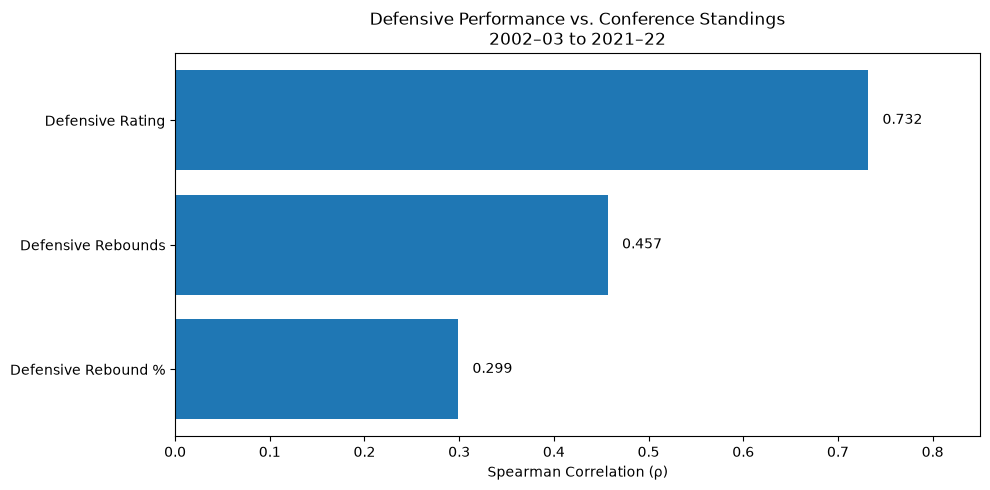

In [104]:
import matplotlib.pyplot as plt

metrics = [
    "Defensive Rating",
    "Defensive Rebounds",
    "Defensive Rebound %"
]

correlations = [0.732, 0.457, 0.299]

plt.figure(figsize=(10, 5))

bars = plt.barh(metrics, correlations)

plt.xlabel("Spearman Correlation (ρ)")
plt.title("Defensive Performance vs. Conference Standings\n2002–03 to 2021–22")

plt.xlim(0, 0.85)
plt.gca().invert_yaxis()

for bar, value in zip(bars, correlations):
    plt.text(
        value + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

plt.tight_layout()
plt.savefig("defensive_correlations.png", dpi=300)
plt.show()

In [105]:
# Rank defensive efficiency within each conference and season
# Lower defensive rating = better defense

rebounds_rankings_df["CONF_DEF_RANK"] = (
    rebounds_rankings_df
    .groupby(["SEASON", "CONFERENCE"])["DEF_RATING"]
    .rank(method="min", ascending=True)
)

display(
    rebounds_rankings_df[
        ["SEASON", "TEAM_NAME", "CONFERENCE",
         "DEF_RATING", "CONF_DEF_RANK", "CONF_RANK"]
    ].head(10)
)

,SEASON,TEAM_NAME,CONFERENCE,DEF_RATING,CONF_DEF_RANK,CONF_RANK
0,2002-03,Atlanta Hawks,East,104.2,10.0,11
1,2002-03,Boston Celtics,East,100.5,5.0,6
2,2002-03,Chicago Bulls,East,104.2,10.0,12
3,2002-03,Cleveland Cavaliers,East,105.1,13.0,15
4,2002-03,Dallas Mavericks,West,101.0,5.0,1
5,2002-03,Denver Nuggets,West,100.1,3.0,14
6,2002-03,Detroit Pistons,East,98.2,2.0,1
7,2002-03,Golden State Warriors,West,107.7,14.0,11
8,2002-03,Houston Rockets,West,100.9,4.0,9
9,2002-03,Indiana Pacers,East,99.6,3.0,3


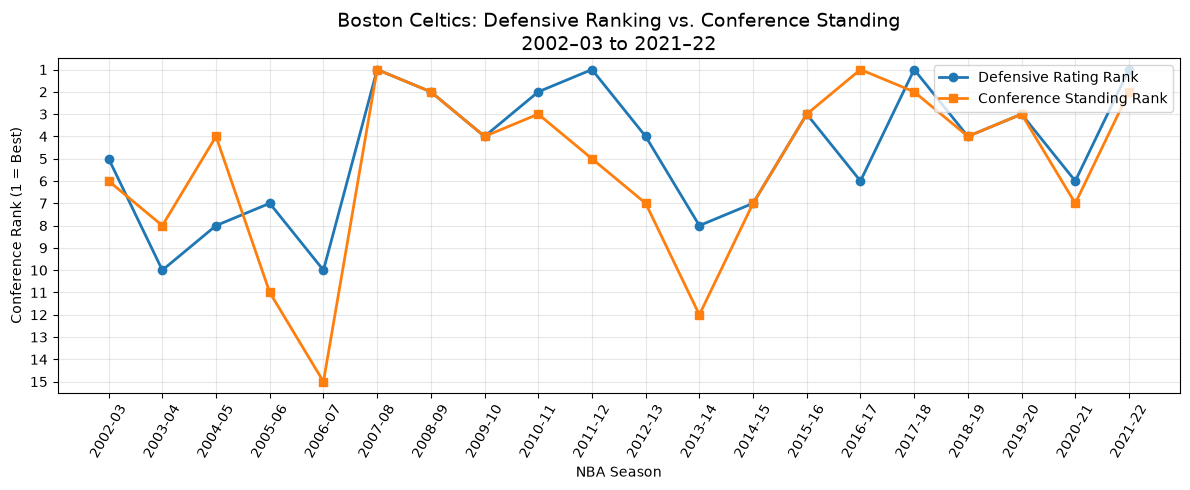

Saved: boston_celtics_defense_vs_standings.png


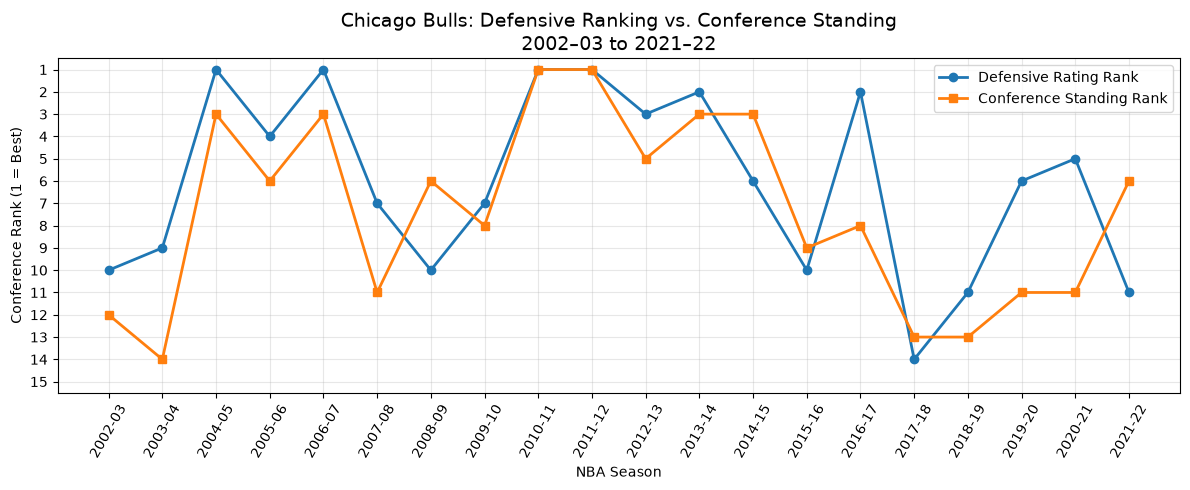

Saved: chicago_bulls_defense_vs_standings.png


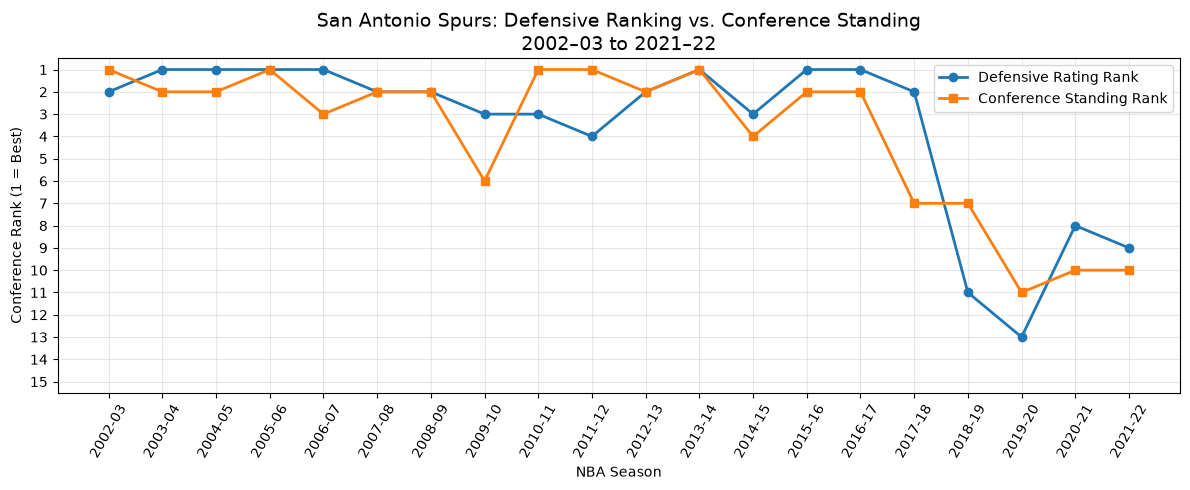

Saved: san_antonio_spurs_defense_vs_standings.png


In [106]:
import matplotlib.pyplot as plt

teams_to_plot = [
    "Boston Celtics",
    "Chicago Bulls",
    "San Antonio Spurs"
]

for team in teams_to_plot:

    team_df = (
        rebounds_rankings_df[
            rebounds_rankings_df["TEAM_NAME"] == team
        ]
        .sort_values("SEASON")
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        team_df["SEASON"],
        team_df["CONF_DEF_RANK"],
        marker="o",
        linewidth=2,
        label="Defensive Rating Rank"
    )

    ax.plot(
        team_df["SEASON"],
        team_df["CONF_RANK"],
        marker="s",
        linewidth=2,
        label="Conference Standing Rank"
    )

    ax.set_title(
        f"{team}: Defensive Ranking vs. Conference Standing\n"
        "2002–03 to 2021–22",
        fontsize=14
    )

    ax.set_xlabel("NBA Season")
    ax.set_ylabel("Conference Rank (1 = Best)")
    ax.set_ylim(15.5, 0.5)
    ax.set_yticks(range(1, 16))

    ax.tick_params(axis="x", rotation=60)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

    plt.tight_layout()

    filename = (
        team.lower().replace(" ", "_")
        + "_defense_vs_standings.png"
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {filename}")

In [107]:
# Rank defensive rebounds and total rebounds within each conference

rebounds_rankings_df["CONF_DREB_RANK"] = (
    rebounds_rankings_df
    .groupby(["SEASON", "CONFERENCE"])["DREB"]
    .rank(method="min", ascending=False)
)

rebounds_rankings_df["CONF_REB_RANK"] = (
    rebounds_rankings_df
    .groupby(["SEASON", "CONFERENCE"])["REB"]
    .rank(method="min", ascending=False)
)

display(
    rebounds_rankings_df[
        ["SEASON", "TEAM_NAME", "DREB", "CONF_DREB_RANK",
         "REB", "CONF_REB_RANK", "CONF_RANK"]
    ].head(10)
)

,SEASON,TEAM_NAME,DREB,CONF_DREB_RANK,REB,CONF_REB_RANK,CONF_RANK
0,2002-03,Atlanta Hawks,31.2,2.0,42.6,6.0,11
1,2002-03,Boston Celtics,30.1,7.0,40.5,12.0,6
2,2002-03,Chicago Bulls,31.0,3.0,43.0,4.0,12
3,2002-03,Cleveland Cavaliers,31.0,3.0,44.6,1.0,15
4,2002-03,Dallas Mavericks,31.0,6.0,42.1,10.0,1
5,2002-03,Denver Nuggets,28.8,14.0,42.4,8.0,14
6,2002-03,Detroit Pistons,29.8,9.0,40.6,11.0,1
7,2002-03,Golden State Warriors,31.0,6.0,46.7,1.0,11
8,2002-03,Houston Rockets,31.3,3.0,43.8,4.0,9
9,2002-03,Indiana Pacers,32.0,1.0,44.2,2.0,3


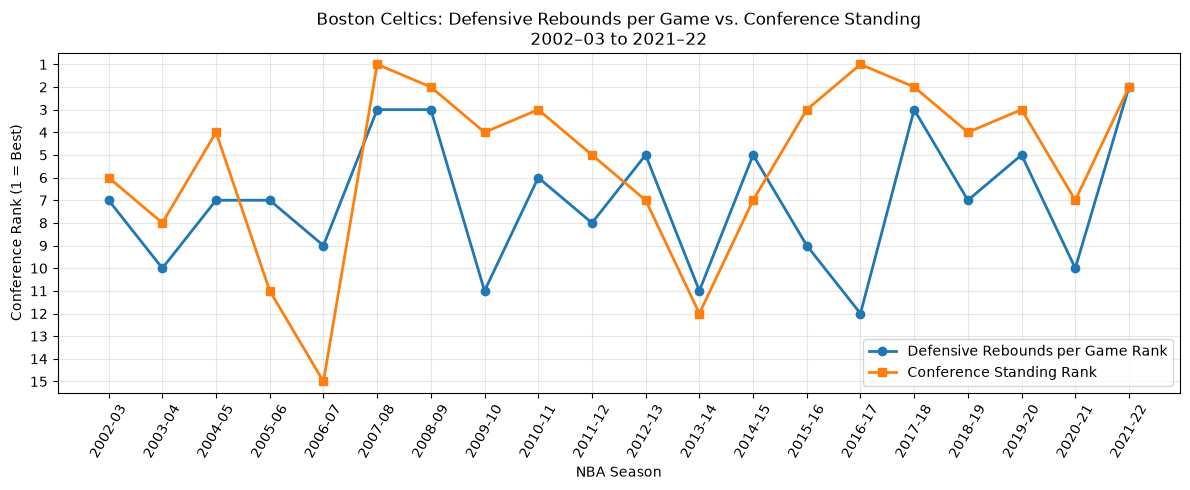

Saved: boston_celtics_conf_dreb_rank.png


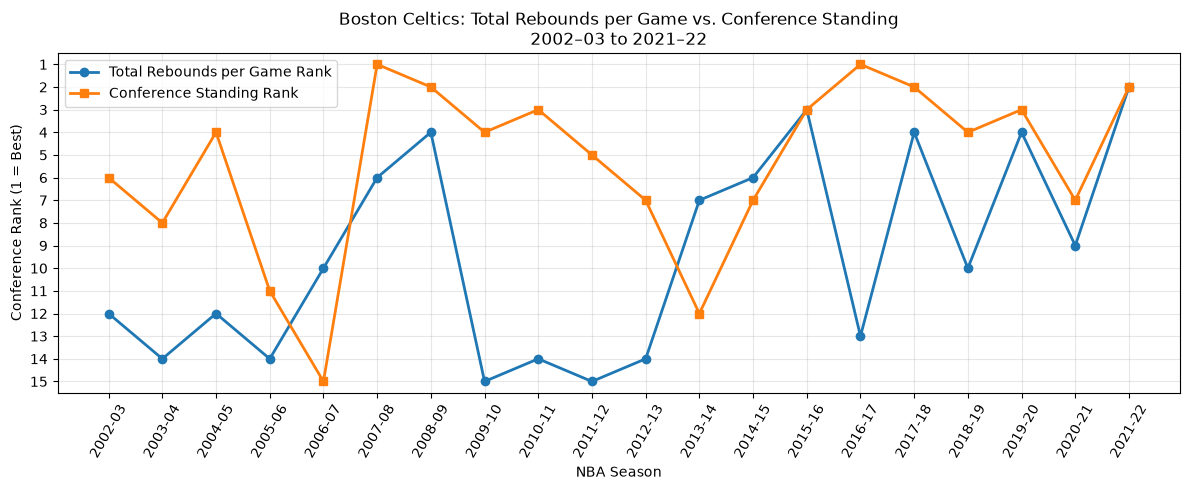

Saved: boston_celtics_conf_reb_rank.png


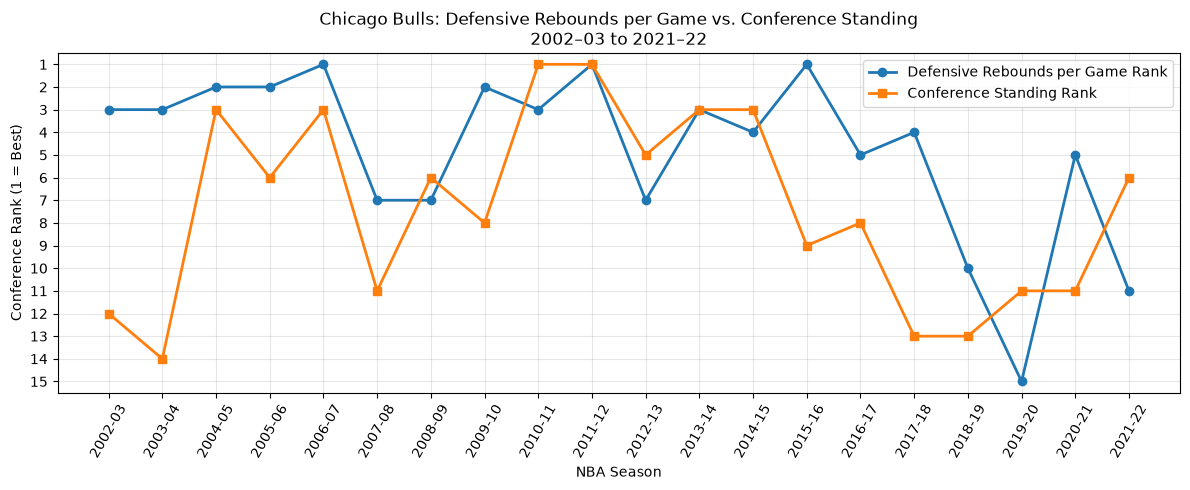

Saved: chicago_bulls_conf_dreb_rank.png


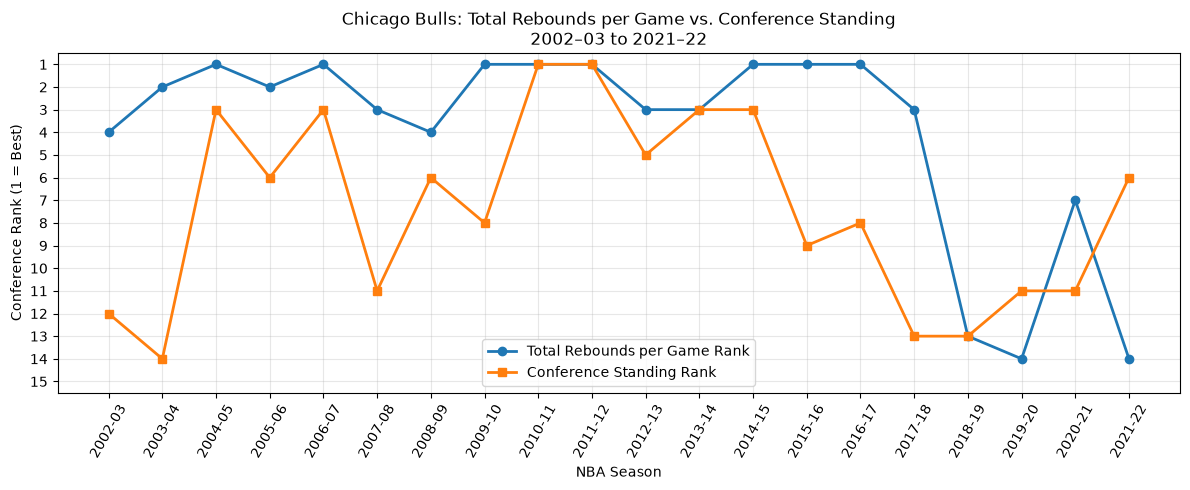

Saved: chicago_bulls_conf_reb_rank.png


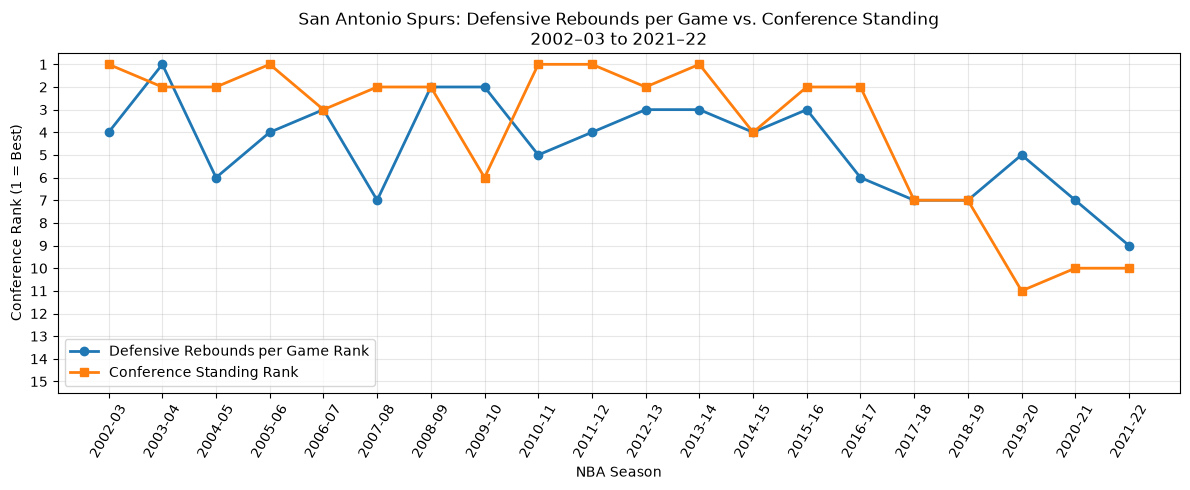

Saved: san_antonio_spurs_conf_dreb_rank.png


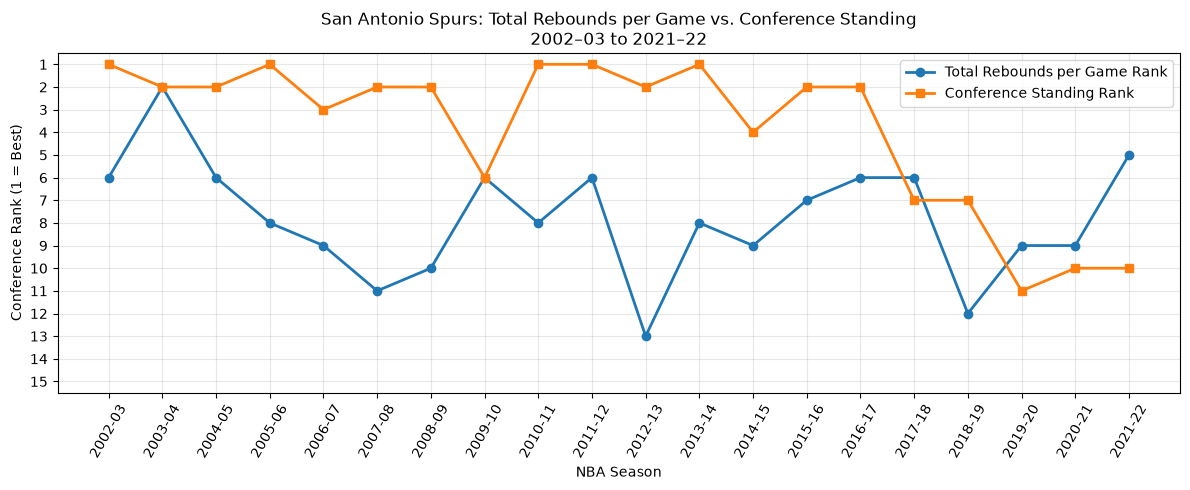

Saved: san_antonio_spurs_conf_reb_rank.png


In [108]:
import matplotlib.pyplot as plt

teams_to_plot = [
    "Boston Celtics",
    "Chicago Bulls",
    "San Antonio Spurs"
]

rebound_metrics = {
    "CONF_DREB_RANK": "Defensive Rebounds per Game",
    "CONF_REB_RANK": "Total Rebounds per Game"
}

for team in teams_to_plot:

    team_df = (
        rebounds_rankings_df[
            rebounds_rankings_df["TEAM_NAME"] == team
        ]
        .sort_values("SEASON")
    )

    for metric, metric_label in rebound_metrics.items():

        fig, ax = plt.subplots(figsize=(12, 5))

        ax.plot(
            team_df["SEASON"],
            team_df[metric],
            marker="o",
            linewidth=2,
            label=metric_label + " Rank"
        )

        ax.plot(
            team_df["SEASON"],
            team_df["CONF_RANK"],
            marker="s",
            linewidth=2,
            label="Conference Standing Rank"
        )

        ax.set_title(
            f"{team}: {metric_label} vs. Conference Standing\n"
            "2002–03 to 2021–22"
        )

        ax.set_xlabel("NBA Season")
        ax.set_ylabel("Conference Rank (1 = Best)")

        # Rank 1 appears at the top
        ax.set_ylim(15.5, 0.5)
        ax.set_yticks(range(1, 16))

        ax.tick_params(axis="x", rotation=60)
        ax.grid(alpha=0.3)
        ax.legend()

        plt.tight_layout()

        filename = (
            team.lower().replace(" ", "_")
            + "_" + metric.lower() + ".png"
        )

        plt.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()

        print(f"Saved: {filename}")

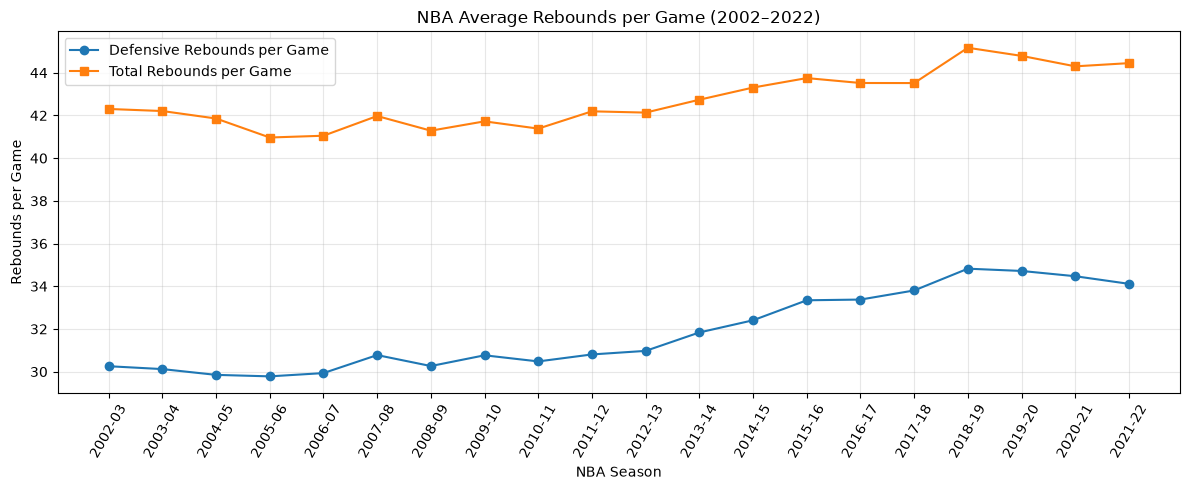

In [109]:
season_rebounds = (
    rebounds_rankings_df
    .groupby("SEASON")[["DREB", "REB"]]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    season_rebounds.index,
    season_rebounds["DREB"],
    marker="o",
    label="Defensive Rebounds per Game"
)

plt.plot(
    season_rebounds.index,
    season_rebounds["REB"],
    marker="s",
    label="Total Rebounds per Game"
)

plt.title("NBA Average Rebounds per Game (2002–2022)")
plt.xlabel("NBA Season")
plt.ylabel("Rebounds per Game")
plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("nba_rebounds_per_game_trend.png", dpi=300)
plt.show()